# Wet AMD Lesion Segmentation — Model 5: MSMamba (Multi-Scale Vision State-Space Network) with Dual-Head Multi-Task Supervision

**Dataset:** AMD-SD (Optical Coherence Tomography Image Dataset for wet AMD Lesions Segmentation — 3,049 B-scans across 156 eyes from 138 patients)

**Architecture Strategy (built on top of the Dual-Head Multi-Task pipeline):**
* **Multi-Scale Convolutional Stem ($1/2$ and $1/4$ scales):** Parallel multi-branch depthwise-separable convolutions ($3 \times 3$, $5 \times 5$, and dilated $3 \times 3$) extract fine-grained local retinal layer boundaries (IS/OS, RPE) alongside variable-sized fluid pockets (IRF, SRF, PED, SHRM).
* **Multi-Scale Vision State-Space Encoder (`MSVSSBlock` at $1/8$ and $1/16$ scales):** Replaces heavy quadratic Transformer self-attention with a **Multi-Scale 2D Selective State-Space (`MultiScaleSS2D`)** module. Each block performs 4-directional 2D spatial scanning (Horizontal Forward/Backward, Vertical Forward/Backward) across both full-resolution and pooled half-resolution token maps using an exact $\mathcal{O}(\log L)$ parallel associative selective scan, followed by a locality-preserving `ConvFFN`.
* **Scale-Aware Gated Cascaded Decoder:** Features from the hierarchical encoder stages are filtered via `MultiScaleSkipGate` blocks and fused across four $\times 2$ upsampling stages back to $512 \times 512$ resolution.
* **Dual-Head Multi-Task Supervision (kept identical to Models 1–4 for direct comparability):** An auxiliary binary lesion head predicts foreground lesion presence ($\text{class} > 0$); its sigmoid probability map is refined via a $7 \times 7$ convolution and concatenated with decoder features prior to the 6-class segmentation head.
* **Identical Training & Evaluation Protocol:** $512 \times 512$ inputs, horizontal flip + $\pm 10^\circ$ rotation, AdamW ($\eta = 10^{-4}$), `PolyLRScheduler`, gradient accumulation (effective batch size 8), joint objective $\mathcal{L}_{\text{MC}} + 0.5 \cdot \mathcal{L}_{\text{BIN}}$, and pixel-pooled `GlobalMetricTracker`.
> **Implementation note.** The state-space layers are a *pure-PyTorch, MSMamba-inspired* re-implementation (log-step parallel associative scan, state size 1, axis-factorised horizontal -> vertical bidirectional scans). They follow the multi-scale idea of MSVMamba (a full-resolution scan plus a half-resolution scan per block) but are **not** the official CUDA `selective_scan` kernel with a 16-d state. That choice is what lets the model train on Apple-Silicon `mps` and plain `cpu` with no custom kernels. Report it as "MSMamba-inspired" in the write-up.
> The only deliberate protocol difference from Models 1-4 is gradient clipping (`max_norm=1.0`) in the training loop, added for state-space stability.


## 1. Setup and Reproducibility
Import dependencies, configure hardware acceleration (`mps`, `cuda`, or `cpu`), and lock random seeds across Python, NumPy, and PyTorch.

In [15]:
import os
import gc
import csv
import math
import time
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, to_rgba
from matplotlib.patches import Patch
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

# Hardware & memory environment variables for Apple Silicon (MPS) and CUDA
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["PYTORCH_MPS_HIGH_WATERMARK_RATIO"] = "0.0"

def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def cleanup_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    elif torch.backends.mps.is_available():
        torch.mps.empty_cache()

SEED = 42
seed_everything(SEED)
cleanup_memory()

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)
print(f"Active Compute Device: {device} | PyTorch {torch.__version__}")

Active Compute Device: mps | PyTorch 2.14.1


### 1.1 Run Configuration
All experiment switches are centralized in this cell:
* `MODEL_VARIANT` — `"base"` (default hierarchical `[48, 96, 192, 384]` channel pyramid) or `"tiny"` (`[32, 64, 128, 256]` lightweight variant).
* `SMOKE_TEST` — Set to `True` to run 1 epoch of 20 train batches and 10 validation batches under a `_smoke` tag to verify end-to-end execution and batch timing before launching the full 20-epoch run.
* `RUN_TRAINING` — Set to `False` to skip training and run evaluation/visualizations on an existing checkpoint.

In [16]:
# ------------------------------- Experiment switches -------------------------------
MODEL_VARIANT = "base"   # "base" (default) or "tiny" (faster lightweight variant)
SMOKE_TEST    = False    # True: 1 epoch x 20 train batches x 10 val batches
RUN_TRAINING  = True     # False: skip training, evaluate existing checkpoint

# ------------------------------- Hyperparameters (match Models 1-4) ----------------
EPOCHS            = 1 if SMOKE_TEST else 35
MAX_TRAIN_BATCHES = 20 if SMOKE_TEST else None
MAX_VAL_BATCHES   = 10 if SMOKE_TEST else None
LEARNING_RATE     = 1e-4
NUM_CLASSES       = 6
IMG_SIZE          = 512

# ------------------------------- File naming (tagged per experiment) ---------------
TAG         = f"msmamba_{MODEL_VARIANT}" + ("_smoke" if SMOKE_TEST else "")
MODEL_KEY   = f"model5_{TAG}"
CKPT_PATH   = f"best_unet_{MODEL_KEY}.pth"
LOG_FILE    = f"{MODEL_KEY}_training_log.csv"
SAVE_PREFIX = MODEL_KEY

print(f"Experiment tag: {TAG}")
print(f"Checkpoint:     {CKPT_PATH} | Training log: {LOG_FILE}")

Experiment tag: msmamba_base
Checkpoint:     best_unet_model5_msmamba_base.pth | Training log: model5_msmamba_base_training_log.csv


## 2. Dataset Pipeline, Unified Color Palette & Target Generation
Loads the pre-sliced $570 \times 380$ OCT B-scans and expert ground-truth masks from `processed_data/` (automatically slicing the raw $1140 \times 380$ composite images from `images/` if `processed_data/` does not exist yet), resizes to $512 \times 512$, applies synchronized training augmentations, and returns `(img_tensor, mask_tensor, bin_tensor)`.

**Color Consistency:** Every plot and segmentation mask in this notebook uses the single `CLASS_PALETTE_RGB` mapping (Background = black, SRF = red, IRF = green, PED = blue, SHRM = yellow, IS/OS = magenta).

In [17]:
CLASS_PALETTE_RGB = np.array([
    [0, 0, 0],        # 0: Background
    [255, 0, 0],      # 1: Subretinal Fluid (SRF)
    [0, 255, 0],      # 2: Intraretinal Fluid (IRF)
    [0, 0, 255],      # 3: Pigment Epithelial Detachment (PED)
    [255, 255, 0],    # 4: Subretinal Hyperreflective Material (SHRM)
    [255, 0, 255]     # 5: Ellipsoid Zone (IS/OS)
], dtype=np.int32)

CLASS_NAMES = ["Background", "SRF", "IRF", "PED", "SHRM", "IS/OS"]
LESION_NAMES = CLASS_NAMES[1:]

# Unified color dictionary for segmentation overlays and statistical plots
CLASS_COLORS_HEX = {n: "#%02x%02x%02x" % tuple(int(v) for v in rgb) for n, rgb in zip(CLASS_NAMES, CLASS_PALETTE_RGB)}
PLOT_COLORS = {**CLASS_COLORS_HEX, "Mean": "#333333"}
SEG_CMAP = ListedColormap(CLASS_PALETTE_RGB / 255.0)

def seg_legend_handles(include_background=True):
    names = CLASS_NAMES if include_background else LESION_NAMES
    return [Patch(facecolor=CLASS_COLORS_HEX[n], edgecolor="black", label=n) for n in names]

def show_seg(ax, mask, title=None):
    ax.imshow(mask, cmap=SEG_CMAP, vmin=0, vmax=5, interpolation="nearest")
    if title:
        ax.set_title(title)
    ax.axis("off")

def ensure_sliced_dataset(base_dir=".", processed_dir="processed_data"):
    """Slices raw 1140x380 composite images into processed_data/ if not already present."""
    train_in = os.path.join(processed_dir, "train", "inputs")
    val_in = os.path.join(processed_dir, "val", "inputs")
    if os.path.exists(train_in) and os.path.exists(val_in) and len(os.listdir(train_in)) > 0:
        return

    images_dir = os.path.join(base_dir, "images")
    for split_file, split_name in [("training.txt", "train"), ("validation.txt", "val")]:
        split_path = os.path.join(base_dir, split_file)
        if not os.path.exists(split_path):
            raise FileNotFoundError(f"Missing {train_in} and split file {split_path}.")
        in_dir = os.path.join(processed_dir, split_name, "inputs")
        out_dir = os.path.join(processed_dir, split_name, "outputs")
        os.makedirs(in_dir, exist_ok=True)
        os.makedirs(out_dir, exist_ok=True)
        with open(split_path, "r") as f:
            files = [line.strip() for line in f if line.strip()]
        for fname in tqdm(files, desc=f"Slicing {split_name}"):
            eye_id = fname.split("_")[0]
            src = os.path.join(images_dir, eye_id, fname)
            img = cv2.imread(src)
            if img is None:
                continue
            mid = img.shape[1] // 2
            base = os.path.splitext(fname)[0]
            cv2.imwrite(os.path.join(in_dir, f"{base}_input.png"), img[:, :mid])
            cv2.imwrite(os.path.join(out_dir, f"{base}_output.png"), img[:, mid:])


class AMDDatasetMSMamba(Dataset):
    def __init__(self, data_root="processed_data", split="train", target_size=(512, 512), augment=True):
        self.inputs_dir = os.path.join(data_root, split, "inputs")
        self.outputs_dir = os.path.join(data_root, split, "outputs")
        self.target_size = target_size
        self.split = split
        self.augment = augment and (split == "train")

        if not os.path.exists(self.inputs_dir):
            raise FileNotFoundError(f"Missing directory: {self.inputs_dir}.")

        self.filenames = sorted([
            f for f in os.listdir(self.inputs_dir)
            if f.endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('.')
        ])

    def __len__(self):
        return len(self.filenames)

    def _rgb_to_class(self, mask_rgb):
        mask = np.ascontiguousarray(mask_rgb, dtype=np.int32)
        dists = np.sum((mask[:, :, None, :] - CLASS_PALETTE_RGB[None, None, :, :]) ** 2, axis=-1)
        return np.argmin(dists, axis=-1)

    def _apply_augmentations(self, img, mask):
        if random.random() > 0.5:
            img = cv2.flip(img, 1)
            mask = cv2.flip(mask, 1)

        angle = random.uniform(-10.0, 10.0)
        h, w = img.shape[:2]
        center = (w // 2, h // 2)
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        mask = cv2.warpAffine(mask, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101)
        return img, mask

    def __getitem__(self, idx):
        in_fname = self.filenames[idx]
        img_path = os.path.join(self.inputs_dir, in_fname)
        out_fname = in_fname.replace("_input", "_output") if "_input" in in_fname else in_fname
        mask_path = os.path.join(self.outputs_dir, out_fname)

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask_bgr = cv2.imread(mask_path)
        if img is None or mask_bgr is None:
            raise ValueError(f"Corrupt image/mask pair at: {img_path}")

        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_LINEAR)
        mask_rgb = cv2.resize(mask_rgb, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_NEAREST)

        mask_labels = self._rgb_to_class(mask_rgb)

        if self.augment:
            img, mask_labels = self._apply_augmentations(img, mask_labels)

        img_arr = np.ascontiguousarray(img, dtype=np.float32) / 255.0
        mask_arr = np.ascontiguousarray(mask_labels, dtype=np.int64)

        img_tensor = torch.from_numpy(img_arr).unsqueeze(0)          # (1, H, W)
        mask_tensor = torch.from_numpy(mask_arr)                     # (H, W)
        bin_tensor = (mask_tensor > 0).float().unsqueeze(0)          # (1, H, W)

        return img_tensor, mask_tensor, bin_tensor


DATA_DIR = "processed_data"
ensure_sliced_dataset( data_root if "data_root" in locals() else ".", DATA_DIR)

MICRO_BATCH_SIZE = 2 if device.type == "mps" else 8
ACCUM_STEPS      = 4 if device.type == "mps" else 1
VAL_BATCH_SIZE   = 2 if device.type == "mps" else 8
NUM_WORKERS      = 0 if device.type == "mps" else 4

train_dataset = AMDDatasetMSMamba(DATA_DIR, split="train", target_size=(IMG_SIZE, IMG_SIZE), augment=True)
val_dataset   = AMDDatasetMSMamba(DATA_DIR, split="val",   target_size=(IMG_SIZE, IMG_SIZE), augment=False)

train_loader = DataLoader(
    train_dataset, batch_size=MICRO_BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda")
)
val_loader = DataLoader(
    val_dataset, batch_size=VAL_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda")
)

print(f"Loaded {len(train_dataset)} train samples and {len(val_dataset)} validation samples.")
print(f"Physical micro-batch: {MICRO_BATCH_SIZE} | accumulation steps: {ACCUM_STEPS} | effective batch: {MICRO_BATCH_SIZE * ACCUM_STEPS}")

Loaded 2346 train samples and 703 validation samples.
Physical micro-batch: 2 | accumulation steps: 4 | effective batch: 8


## 3. Model 5 Architecture Definition: MSMamba Dual-Head Network (MPS/CUDA Optimized)

The **MSMambaDualHead** architecture integrates multi-scale convolutional feature extraction with 2D multi-directional selective state-space sequence modeling:

1. **Multi-Scale Convolutional Stem (`MultiScaleConvBlock` at $1/2$ and $1/4$ scales):**
   * Applies three parallel depthwise branches ($3\times 3$ local, $5\times 5$ medium, and dilated $3\times 3$ wide-receptive-field convolutions) followed by channel mixing.
2. **Multi-Scale 2D Selective State-Space Module (`MultiScaleSS2D` & `MSVSSBlock` at $1/8$ and $1/16$ scales):**
   * Splits feature channels into a **Full-Resolution 2D Scan Branch** ($H \times W$) and a **Pooled Half-Resolution 2D Scan Branch** ($H/2 \times W/2$).
   * Each `SS2D` module performs **4-directional 2D selective scanning** via cascaded bidirectional Horizontal ($\leftrightarrow$) and bidirectional Vertical ($\updownarrow$) parallel associative scans (`parallel_selective_scan_1d`), achieving a full 2D global receptive field in $\mathcal{O}(\log_2 H + \log_2 W)$ steps with zero MPS CPU fallbacks.
3. **Scale-Aware Gated Skip Connections (`MultiScaleSkipGate`) & Cascaded Decoder:**
   * Filters encoder skip maps at $1/8$, $1/4$, and $1/2$ scales using coarse decoder context gates before bilinear upsampling and `DoubleConv` refinement back to $512 \times 512$.
4. **Dual-Head Multi-Task Output (matching Models 1–4):**
   * `binary_head` predicts binary lesion logits $\to$ sigmoid probability map $\to$ `refine_kernel7` ($7\times 7$ conv) $\to$ concatenated with decoder features $\to$ `multiclass_head` outputs 6-class logits `(mc_logits, binary_logits)`.
5. **What was fixed / changed in this version:** (i) a typo (`classSS2D`) that made the architecture cell a `SyntaxError` is corrected; (ii) the continuous decay `A` of every SSM channel is now initialised to a *spread* of time-scales (S4D-style, `A in [e^-1, e^1.5]`) instead of one identical value, so different channels remember over different distances - this is what makes the scan genuinely multi-scale rather than 96 copies of one filter.


In [18]:
class DoubleConv(nn.Module):
    """[Conv2d -> BatchNorm -> ReLU] * 2"""
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class MultiScaleConvBlock(nn.Module):
    """
    Multi-Scale Convolutional Block for high-resolution stages (1/2 and 1/4).
    Extracts features simultaneously via 3x3, 5x5, and dilated 3x3 (d=2) depthwise branches.
    """
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.proj_in = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.SiLU(inplace=True),
        )
        self.dw_3x3 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, groups=out_channels, bias=False)
        self.dw_5x5 = nn.Conv2d(out_channels, out_channels, kernel_size=5, padding=2, groups=out_channels, bias=False)
        self.dw_dil = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=2, dilation=2, groups=out_channels, bias=False)

        self.bn = nn.BatchNorm2d(out_channels * 3)
        self.act = nn.SiLU(inplace=True)
        self.proj_out = nn.Sequential(
            nn.Conv2d(out_channels * 3, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        self.shortcut = (
            nn.Identity() if in_channels == out_channels
            else nn.Sequential(nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False), nn.BatchNorm2d(out_channels))
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.proj_in(x)
        ms = torch.cat([self.dw_3x3(h), self.dw_5x5(h), self.dw_dil(h)], dim=1)
        out = self.proj_out(self.act(self.bn(ms)))
        return F.silu(out + self.shortcut(x))


def reverse_along_last_dim(x: torch.Tensor) -> torch.Tensor:
    """Reverses a tensor along its last dimension using on-device indexing (avoids MPS CPU fallback)."""
    idx = torch.arange(x.size(-1) - 1, -1, -1, device=x.device, dtype=torch.long)
    return x.index_select(-1, idx)


def parallel_selective_scan_1d(u: torch.Tensor, delta: torch.Tensor, A: torch.Tensor,
                               B_weight: torch.Tensor, C_weight: torch.Tensor, D_skip: torch.Tensor) -> torch.Tensor:
    """
    Fast O(log2 S) parallel associative selective scan along the last dimension S (S <= 64).
    Solves h_t = exp(delta_t * A) * h_{t-1} + (delta_t * B_t) * u_t, y_t = C_t * h_t + D * u_t.

    All tensors have shape (Batch, Channels, Spatial_Ortho, Sequence_Length S).
    Runs 100% natively on MPS, CUDA, and CPU with minimal autograd memory.
    """
    S = u.shape[-1]
    a = torch.exp(delta * A)           # (B, C, P, S) in (0, 1)
    b = (delta * B_weight) * u         # (B, C, P, S)

    step = 1
    while step < S:
        a_prev = a[..., :-step]
        b_prev = b[..., :-step]
        a_curr = a[..., step:]
        b_curr = b[..., step:]
        b = torch.cat([b[..., :step], a_curr * b_prev + b_curr], dim=-1)
        a = torch.cat([a[..., :step], a_curr * a_prev], dim=-1)
        step *= 2

    return C_weight * b + D_skip * u


class SS2D(nn.Module):
    """
    Axis-Factorized 4-Way 2D Selective State-Space Module:
      1. Bidirectional Horizontal Scan (Left->Right & Right->Left, length W <= 64)
      2. Bidirectional Vertical Scan   (Top->Bottom & Bottom->Top, length H <= 64)
    Cascading horizontal and vertical selective scans gives every pixel a full 2D global receptive field
    in log2(W) + log2(H) steps without 5D memory blowup.
    """
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim
        self.dw_conv = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim, bias=True)
        self.act = nn.SiLU(inplace=True)

        # Input-dependent SSM parameter generators (delta, B, C) for Horizontal (fwd/bwd) and Vertical (fwd/bwd)
        self.h_param_proj = nn.Conv2d(dim, dim * 6, kernel_size=1, bias=True)
        self.v_param_proj = nn.Conv2d(dim, dim * 6, kernel_size=1, bias=True)

        # Learnable continuous decay A_log and skip D for (2 directions x dim)
        # S4D-style spread of time-scales (same spread for the fwd and bwd copy of each direction)
        a_init = torch.linspace(-1.0, 1.5, dim).repeat(2).view(1, dim * 2, 1, 1)
        self.A_h_log = nn.Parameter(a_init.clone())
        self.D_h     = nn.Parameter(torch.ones(1, dim * 2, 1, 1))
        self.A_v_log = nn.Parameter(a_init.clone())
        self.D_v     = nn.Parameter(torch.ones(1, dim * 2, 1, 1))

        self.out_norm = nn.GroupNorm(1, dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.act(self.dw_conv(x))

        # --- Stage 1: Bidirectional Horizontal Selective Scan (along W) ---
        dt_h, B_h, C_h = self.h_param_proj(x).chunk(3, dim=1)          # each (B, 2*C, H, W)
        delta_h = F.softplus(dt_h) * 0.1
        B_h = torch.tanh(B_h)
        C_h = torch.tanh(C_h)
        A_h = -torch.exp(self.A_h_log.clamp(min=-4.0, max=2.0))

        u_h = torch.cat([x, reverse_along_last_dim(x)], dim=1)         # (B, 2*C, H, W)
        y_h_both = parallel_selective_scan_1d(u_h, delta_h, A_h, B_h, C_h, self.D_h)
        y_h_fwd, y_h_bwd = y_h_both.chunk(2, dim=1)
        x_h = y_h_fwd + reverse_along_last_dim(y_h_bwd)                # (B, C, H, W)

        # --- Stage 2: Bidirectional Vertical Selective Scan (along H, transposed to last dim) ---
        x_ht = x_h.transpose(-2, -1).contiguous()                      # (B, C, W, H)
        dt_v, B_v, C_v = self.v_param_proj(x_ht).chunk(3, dim=1)       # each (B, 2*C, W, H)
        delta_v = F.softplus(dt_v) * 0.1
        B_v = torch.tanh(B_v)
        C_v = torch.tanh(C_v)
        A_v = -torch.exp(self.A_v_log.clamp(min=-4.0, max=2.0))

        u_v = torch.cat([x_ht, reverse_along_last_dim(x_ht)], dim=1)   # (B, 2*C, W, H)
        y_v_both = parallel_selective_scan_1d(u_v, delta_v, A_v, B_v, C_v, self.D_v)
        y_v_fwd, y_v_bwd = y_v_both.chunk(2, dim=1)
        y_v = (y_v_fwd + reverse_along_last_dim(y_v_bwd)).transpose(-2, -1).contiguous()

        return self.out_norm(x_h + y_v)


class MultiScaleSS2D(nn.Module):
    """
    Multi-Scale 2D Selective State-Space Mixer (MSMamba Core):
    Splits channels into a Full-Resolution SS2D branch (H x W) and a Pooled Half-Resolution SS2D branch (H/2 x W/2).
    """
    def __init__(self, dim: int):
        super().__init__()
        self.half_dim = dim // 2
        self.in_proj = nn.Conv2d(dim, dim * 2, kernel_size=1, bias=False)

        # Branch 1: Full-resolution 2D selective scan
        self.ss2d_full = SS2D(self.half_dim)

        # Branch 2: Half-resolution 2D selective scan
        self.down_pool = nn.Conv2d(
            self.half_dim, self.half_dim, kernel_size=3, stride=2, padding=1,
            groups=self.half_dim, bias=False
        )
        self.ss2d_half = SS2D(self.half_dim)

        self.out_proj = nn.Conv2d(dim, dim, kernel_size=1, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        xz = self.in_proj(x)
        x_branch, z_gate = xz.chunk(2, dim=1)
        x_full, x_half = x_branch.chunk(2, dim=1)

        y_full = self.ss2d_full(x_full)
        y_half = self.ss2d_half(self.down_pool(x_half))
        y_half = F.interpolate(y_half, size=x.shape[-2:], mode="bilinear", align_corners=False)

        y = torch.cat([y_full, y_half], dim=1) * F.silu(z_gate)
        return self.out_proj(y)


class ConvFFN(nn.Module):
    """Locality-Enhanced Convolutional Feed-Forward Network."""
    def __init__(self, dim: int, expansion: int = 2):
        super().__init__()
        hidden = dim * expansion
        self.net = nn.Sequential(
            nn.Conv2d(dim, hidden, kernel_size=1, bias=False),
            nn.BatchNorm2d(hidden),
            nn.SiLU(inplace=True),
            nn.Conv2d(hidden, hidden, kernel_size=3, padding=1, groups=hidden, bias=False),
            nn.BatchNorm2d(hidden),
            nn.SiLU(inplace=True),
            nn.Conv2d(hidden, dim, kernel_size=1, bias=False),
            nn.BatchNorm2d(dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class MSVSSBlock(nn.Module):
    """Multi-Scale Vision State-Space Block: Norm -> MultiScaleSS2D -> Residual -> Norm -> ConvFFN -> Residual."""
    def __init__(self, dim: int):
        super().__init__()
        self.norm1 = nn.GroupNorm(1, dim)
        self.ms_ssm = MultiScaleSS2D(dim)
        self.norm2 = nn.GroupNorm(1, dim)
        self.ffn = ConvFFN(dim, expansion=2)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.ms_ssm(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x


class MultiScaleSkipGate(nn.Module):
    """Scale-aware spatial attention gate to refine skip features using decoder context."""
    def __init__(self, skip_channels: int, dec_channels: int):
        super().__init__()
        inter = max(16, skip_channels // 2)
        self.W_skip = nn.Sequential(
            nn.Conv2d(skip_channels, inter, kernel_size=1, bias=False),
            nn.BatchNorm2d(inter),
        )
        self.W_dec = nn.Sequential(
            nn.Conv2d(dec_channels, inter, kernel_size=1, bias=False),
            nn.BatchNorm2d(inter),
        )
        self.psi = nn.Sequential(
            nn.SiLU(inplace=True),
            nn.Conv2d(inter, 1, kernel_size=3, padding=1, bias=True),
            nn.Sigmoid(),
        )

    def forward(self, skip: torch.Tensor, dec: torch.Tensor) -> torch.Tensor:
        attn = self.psi(self.W_skip(skip) + self.W_dec(dec))
        return skip * attn


class MSMambaDecoderBlock(nn.Module):
    """x2 Bilinear Upsample -> MultiScaleSkipGate -> Concat -> DoubleConv."""
    def __init__(self, in_channels: int, skip_channels: int, out_channels: int):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.has_skip = skip_channels > 0
        if self.has_skip:
            self.gate = MultiScaleSkipGate(skip_channels, in_channels)
        self.conv = DoubleConv(in_channels + skip_channels, out_channels)

    def forward(self, x: torch.Tensor, skip: torch.Tensor = None) -> torch.Tensor:
        x = self.up(x)
        if self.has_skip and skip is not None:
            skip = self.gate(skip, x)
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class MSMambaDualHead(nn.Module):
    """
    Model 5: Hierarchical MSMamba Encoder-Decoder + Dual-Head Multi-Task Supervision.
    Outputs (mc_logits, binary_logits) matching Models 1-4.
    """
    def __init__(self, in_channels: int = 1, num_classes: int = 6, img_size: int = 512, variant: str = "base"):
        super().__init__()
        assert img_size % 16 == 0, "img_size must be divisible by 16"
        dims = (32, 64, 128, 256) if variant == "tiny" else (48, 96, 192, 384)
        c0, c1, c2, c3 = dims
        dec_dims = (192, 96, 48, 16) if variant == "base" else (128, 64, 32, 16)

        # Stage 0 (1/2 resolution: 256x256) - Multi-Scale Conv Stem
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, c0, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(c0),
            nn.SiLU(inplace=True),
            MultiScaleConvBlock(c0, c0),
        )

        # Stage 1 (1/4 resolution: 128x128) - Multi-Scale Conv Stage
        self.down1 = nn.Sequential(
            nn.Conv2d(c0, c1, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(c1),
            nn.SiLU(inplace=True),
            MultiScaleConvBlock(c1, c1),
            MultiScaleConvBlock(c1, c1),
        )

        # Stage 2 (1/8 resolution: 64x64) - Hierarchical MSVSS Stage
        self.down2 = nn.Sequential(
            nn.Conv2d(c1, c2, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(c2),
            nn.SiLU(inplace=True),
            MSVSSBlock(c2),
            MSVSSBlock(c2),
        )

        # Stage 3 / Bottleneck (1/16 resolution: 32x32) - Deep MSVSS Stage
        self.bottleneck = nn.Sequential(
            nn.Conv2d(c2, c3, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(c3),
            nn.SiLU(inplace=True),
            MSVSSBlock(c3),
            MSVSSBlock(c3),
        )

        # Cascaded Decoder with Gated Multi-Scale Skips
        self.dec1 = MSMambaDecoderBlock(c3, c2, dec_dims[0])          # 32 -> 64   (skip s2: 1/8)
        self.dec2 = MSMambaDecoderBlock(dec_dims[0], c1, dec_dims[1]) # 64 -> 128  (skip s1: 1/4)
        self.dec3 = MSMambaDecoderBlock(dec_dims[1], c0, dec_dims[2]) # 128 -> 256 (skip s0: 1/2)
        self.dec4 = MSMambaDecoderBlock(dec_dims[2], 0, dec_dims[3])  # 256 -> 512 (full res)

        c_final = dec_dims[3]

        # Head 1: Auxiliary binary lesion detection head (class > 0)
        self.binary_head = nn.Conv2d(c_final, 1, kernel_size=1)

        # 7x7 spatial guidance refinement on binary probabilities
        self.refine_kernel7 = nn.Sequential(
            nn.Conv2d(1, c_final, kernel_size=7, padding=3, bias=False),
            nn.BatchNorm2d(c_final),
            nn.ReLU(inplace=True),
        )

        # Head 2: Multi-class segmentation head (Background + 5 wet AMD lesions)
        self.multiclass_head = nn.Sequential(
            DoubleConv(c_final * 2, c_final),
            nn.Conv2d(c_final, num_classes, kernel_size=1),
        )

    def forward_encoder(self, x: torch.Tensor):
        s0 = self.stem(x)          # (B, c0, H/2, W/2)
        s1 = self.down1(s0)        # (B, c1, H/4, W/4)
        s2 = self.down2(s1)        # (B, c2, H/8, W/8)
        b  = self.bottleneck(s2)   # (B, c3, H/16, W/16)
        return b, [s2, s1, s0]

    def forward(self, x: torch.Tensor):
        b, skips = self.forward_encoder(x)
        d = self.dec1(b, skips[0])
        d = self.dec2(d, skips[1])
        d = self.dec3(d, skips[2])
        dec_features = self.dec4(d, None)  # (B, 16, H, W)

        binary_logits = self.binary_head(dec_features)
        guidance = self.refine_kernel7(torch.sigmoid(binary_logits))
        fused = torch.cat([dec_features, guidance], dim=1)
        mc_logits = self.multiclass_head(fused)
        return mc_logits, binary_logits


def load_model5(ckpt_path: str, variant: str = MODEL_VARIANT):
    """Instantiate MSMambaDualHead and load saved checkpoint weights for evaluation."""
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(f"Checkpoint not found at '{ckpt_path}'. Train the model first.")
    net = MSMambaDualHead(in_channels=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, variant=variant).to(device)
    net.load_state_dict(torch.load(ckpt_path, map_location=device))
    net.eval()
    return net

### 3.1 Architecture Sanity Check
Verifies the forward pass, hierarchical encoder feature shapes, multi-scale MSVSS bottleneck dimensions, dual-head output shapes, and parameter count on a synthetic batch `(2, 1, 512, 512)`.

In [19]:
test_net = MSMambaDualHead(in_channels=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, variant=MODEL_VARIANT).to(device)
test_net.train()
dummy_in = torch.randn(2, 1, IMG_SIZE, IMG_SIZE, device=device)

# Time 1 full forward + backward pass on your device
t0 = time.time()
bottleneck_map, skips = test_net.forward_encoder(dummy_in)
test_mc, test_bin = test_net(dummy_in)
loss_dummy = test_mc.mean() + test_bin.mean()
loss_dummy.backward()
if device.type == "mps":
    torch.mps.synchronize()
elif device.type == "cuda":
    torch.cuda.synchronize()
step_ms = (time.time() - t0) * 1000.0

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

enc_params = count_params(test_net.stem) + count_params(test_net.down1) + count_params(test_net.down2) + count_params(test_net.bottleneck)
dec_params = count_params(test_net.dec1) + count_params(test_net.dec2) + count_params(test_net.dec3) + count_params(test_net.dec4)

print(f"MSMamba variant:                 {MODEL_VARIANT}")
print(f"MSVSS bottleneck feature map:    {tuple(bottleneck_map.shape)}")
print(f"Multi-scale skips (1/8,1/4,1/2): {[tuple(s.shape) for s in skips]}")
print(f"Multi-class logits shape:        {tuple(test_mc.shape)}")
print(f"Binary logits shape:             {tuple(test_bin.shape)}")
print(f"Encoder (MSConv + MSVSS) params: {enc_params:,}")
print(f"Decoder (Gated Up) params:       {dec_params:,}")
print(f"Total trainable parameters:      {count_params(test_net):,}")
print(f"1-Batch Forward+Backward time:   {step_ms:.1f} ms")

assert test_mc.shape == (2, NUM_CLASSES, IMG_SIZE, IMG_SIZE)
assert test_bin.shape == (2, 1, IMG_SIZE, IMG_SIZE)
print("\nMSMambaDualHead forward + backward pass verified!")

del test_net, dummy_in, bottleneck_map, skips, test_mc, test_bin, loss_dummy
cleanup_memory()

MSMamba variant:                 base
MSVSS bottleneck feature map:    (2, 384, 32, 32)
Multi-scale skips (1/8,1/4,1/2): [(2, 192, 64, 64), (2, 96, 128, 128), (2, 48, 256, 256)]
Multi-class logits shape:        (2, 6, 512, 512)
Binary logits shape:             (2, 1, 512, 512)
Encoder (MSConv + MSVSS) params: 5,839,680
Decoder (Gated Up) params:       1,827,211
Total trainable parameters:      7,674,802
1-Batch Forward+Backward time:   979.7 ms

MSMambaDualHead forward + backward pass verified!


## 4. Multi-Task Objective, Global Metric Accumulation, and Learning Rate Schedule
Uses the exact same multi-task loss $\mathcal{L}_{\text{Total}} = \mathcal{L}_{\text{MC}} + 0.5 \cdot \mathcal{L}_{\text{BIN}}$, pixel-pooled `GlobalMetricTracker`, and `PolyLRScheduler` as Models 1–4 for a controlled architectural comparison.

In [20]:
class MultiTaskLoss(nn.Module):
    def __init__(self, num_classes: int = 6, ignore_index: int = 255, binary_weight: float = 0.5,
                 ce_weight: float = 0.5, dice_weight: float = 0.5, smooth: float = 1.0):
        super().__init__()
        self.num_classes = num_classes
        self.ignore_index = ignore_index
        self.binary_weight = binary_weight
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight
        self.smooth = smooth
        self.ce = nn.CrossEntropyLoss(ignore_index=ignore_index)

    def forward(self, mc_logits: torch.Tensor, bin_logits: torch.Tensor,
                targets: torch.Tensor, bin_targets: torch.Tensor):
        # 1. Multi-Class Loss (CE + Foreground Soft Dice across classes 1..5)
        ce_loss = self.ce(mc_logits, targets)
        probs = F.softmax(mc_logits, dim=1)
        valid_mask = (targets != self.ignore_index)

        targets_clean = targets.clone()
        targets_clean[~valid_mask] = 0
        targets_one_hot = F.one_hot(targets_clean, num_classes=self.num_classes).permute(0, 3, 1, 2).float()

        dice_total = 0.0
        for c in range(1, self.num_classes):
            p = probs[:, c, ...][valid_mask]
            t = targets_one_hot[:, c, ...][valid_mask]
            intersection = (p * t).sum()
            dice = (2.0 * intersection + self.smooth) / (p.sum() + t.sum() + self.smooth)
            dice_total += (1.0 - dice)

        mc_dice_loss = dice_total / (self.num_classes - 1)
        l_mc = (self.ce_weight * ce_loss) + (self.dice_weight * mc_dice_loss)

        # 2. Auxiliary Binary Lesion Detection Loss (BCE + Binary Soft Dice)
        valid_mask_bin = valid_mask.unsqueeze(1)
        b_logits_valid = bin_logits[valid_mask_bin]
        b_targets_valid = bin_targets[valid_mask_bin]

        bce_loss = F.binary_cross_entropy_with_logits(b_logits_valid, b_targets_valid)
        b_probs = torch.sigmoid(b_logits_valid)
        b_intersection = (b_probs * b_targets_valid).sum()
        b_dice = (2.0 * b_intersection + self.smooth) / (b_probs.sum() + b_targets_valid.sum() + self.smooth)
        b_dice_loss = 1.0 - b_dice

        l_bin = (0.5 * bce_loss) + (0.5 * b_dice_loss)

        total_loss = l_mc + (self.binary_weight * l_bin)
        return total_loss, l_mc, l_bin


class GlobalMetricTracker:
    """Pixel-pooled Dice / IoU over the entire validation split (AMD-SD Table 3 protocol)."""
    def __init__(self, num_classes: int = 6):
        self.num_classes = num_classes
        self.class_map = {1: "SRF", 2: "IRF", 3: "PED", 4: "SHRM", 5: "IS/OS"}
        self.reset()

    def reset(self):
        self.intersections = {c: 0.0 for c in range(1, self.num_classes)}
        self.total_preds = {c: 0.0 for c in range(1, self.num_classes)}
        self.total_targets = {c: 0.0 for c in range(1, self.num_classes)}

    def update(self, preds: torch.Tensor, targets: torch.Tensor):
        for c in range(1, self.num_classes):
            p = (preds == c).float()
            t = (targets == c).float()
            self.intersections[c] += (p * t).sum().item()
            self.total_preds[c] += p.sum().item()
            self.total_targets[c] += t.sum().item()

    def compute(self):
        dice_scores, iou_scores = {}, {}
        for c, name in self.class_map.items():
            inter = self.intersections[c]
            p_sum = self.total_preds[c]
            t_sum = self.total_targets[c]
            union = p_sum + t_sum - inter

            dice = (2.0 * inter) / (p_sum + t_sum + 1e-8) * 100.0
            iou = inter / (union + 1e-8) * 100.0
            dice_scores[name] = dice
            iou_scores[name] = iou

        mean_dice = sum(dice_scores.values()) / len(dice_scores)
        mean_iou = sum(iou_scores.values()) / len(iou_scores)
        return dice_scores, iou_scores, mean_dice, mean_iou


class PolyLRScheduler(torch.optim.lr_scheduler._LRScheduler):
    def __init__(self, optimizer, max_epochs, power=0.9, min_lr=1e-6, last_epoch=-1):
        self.max_epochs = max_epochs
        self.power = power
        self.min_lr = min_lr
        super().__init__(optimizer, last_epoch)

    def get_lr(self):
        factor = (1.0 - self.last_epoch / max(1, self.max_epochs)) ** self.power
        return [max(self.min_lr, base_lr * factor) for base_lr in self.base_lrs]

## 5. Supervised Training Loop & Checkpointing
Trains **Model 5 (MSMambaDualHead)** using AdamW ($\eta = 10^{-4}$, weight decay $10^{-4}$), gradient accumulation (effective batch size 8), and polynomial learning rate decay. Saves the highest validation Mean Dice weights to `best_unet_model5_<tag>.pth` and logs per-epoch metrics to `model5_<tag>_training_log.csv`.

In [21]:
def run_model5_training():
    cleanup_memory()
    seed_everything(SEED)

    LOG_EVERY = 5 if SMOKE_TEST else 50     # print a progress line every N micro-batches

    model = MSMambaDualHead(
        in_channels=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, variant=MODEL_VARIANT
    ).to(device)
    criterion = MultiTaskLoss(
        num_classes=NUM_CLASSES, ignore_index=255, binary_weight=0.5,
        ce_weight=0.5, dice_weight=0.5, smooth=1.0
    ).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    scheduler = PolyLRScheduler(optimizer, max_epochs=EPOCHS, power=0.9, min_lr=1e-6)

    n_train_steps = len(train_loader) if MAX_TRAIN_BATCHES is None else min(len(train_loader), MAX_TRAIN_BATCHES)
    n_val_steps = len(val_loader) if MAX_VAL_BATCHES is None else min(len(val_loader), MAX_VAL_BATCHES)

    fieldnames = [
        "epoch", "train_loss", "val_loss", "mean_dice", "mean_iou",
        "SRF_dice", "IRF_dice", "PED_dice", "SHRM_dice", "IS_OS_dice",
        "SRF_iou", "IRF_iou", "PED_iou", "SHRM_iou", "IS_OS_iou"
    ]
    with open(LOG_FILE, "w", newline="") as f:
        csv.DictWriter(f, fieldnames=fieldnames).writeheader()

    best_mean_dice = 0.0
    run_start = time.time()
    print(f"Beginning Model 5 Training (MSMamba dual-head | variant={MODEL_VARIANT} | tag={TAG})", flush=True)
    print(f"{n_train_steps} train steps/epoch, {n_val_steps} val steps/epoch, {EPOCHS} epoch(s) | "
          f"progress printed every {LOG_EVERY} steps", flush=True)

    for epoch in range(1, EPOCHS + 1):
        t_epoch = time.time()
        model.train()
        train_loss_accum = 0.0
        optimizer.zero_grad(set_to_none=True)

        # ------------------------------ Train ------------------------------
        for step, (images, mc_targets, bin_targets) in enumerate(train_loader):
            if step >= n_train_steps:
                break
            images = images.to(device)
            mc_targets = mc_targets.to(device, dtype=torch.long)
            bin_targets = bin_targets.to(device, dtype=torch.float32)

            mc_logits, bin_logits = model(images)
            loss, l_mc, l_bin = criterion(mc_logits, bin_logits, mc_targets, bin_targets)

            (loss / ACCUM_STEPS).backward()

            if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == n_train_steps:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)

            train_loss_accum += loss.item()          # .item() also forces the device to finish this step

            done = step + 1
            if done == 1 or done % LOG_EVERY == 0 or done == n_train_steps:
                elapsed = time.time() - t_epoch
                sec_per_step = elapsed / done
                eta_min = sec_per_step * (n_train_steps - done) / 60.0
                print(f"Epoch {epoch:02d}/{EPOCHS} [Train] step {done:4d}/{n_train_steps} "
                      f"({100.0 * done / n_train_steps:5.1f}%) | loss {loss.item():.4f} "
                      f"(running avg {train_loss_accum / done:.4f}) | mc {l_mc.item():.3f} bin {l_bin.item():.3f} | "
                      f"{sec_per_step:.2f} s/step | epoch ETA {eta_min:.1f} min", flush=True)

        scheduler.step()
        epoch_train_loss = train_loss_accum / n_train_steps

        # ---------------------------- Validation ----------------------------
        print(f"Epoch {epoch:02d}/{EPOCHS} [Val] started ({n_val_steps} steps)...", flush=True)
        model.eval()
        val_loss_accum = 0.0
        metric_tracker = GlobalMetricTracker(num_classes=NUM_CLASSES)
        t_val = time.time()
        val_log_every = max(LOG_EVERY * 2, 1)

        with torch.no_grad():
            for vstep, (images, mc_targets, bin_targets) in enumerate(val_loader):
                if vstep >= n_val_steps:
                    break
                images = images.to(device)
                mc_targets = mc_targets.to(device, dtype=torch.long)
                bin_targets = bin_targets.to(device, dtype=torch.float32)

                mc_logits, bin_logits = model(images)
                loss, _, _ = criterion(mc_logits, bin_logits, mc_targets, bin_targets)
                val_loss_accum += loss.item()

                preds = torch.argmax(mc_logits, dim=1)
                metric_tracker.update(preds, mc_targets)

                vdone = vstep + 1
                if vdone % val_log_every == 0 or vdone == n_val_steps:
                    print(f"Epoch {epoch:02d}/{EPOCHS} [Val]   step {vdone:4d}/{n_val_steps} "
                          f"({100.0 * vdone / n_val_steps:5.1f}%) | {(time.time() - t_val) / 60:.1f} min", flush=True)

        epoch_val_loss = val_loss_accum / n_val_steps
        avg_dice, avg_iou, mean_dice, mean_iou = metric_tracker.compute()

        epochs_left = EPOCHS - epoch
        epoch_min = (time.time() - t_epoch) / 60.0
        print(f"\n=== Epoch {epoch:02d}/{EPOCHS} Summary (Model 5 | {TAG}) === "
              f"[{epoch_min:.1f} min | total {(time.time() - run_start) / 60:.1f} min | "
              f"~{epoch_min * epochs_left / 60:.1f} h remaining]", flush=True)
        print(f"Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")
        print(f"Mean Dice:  {mean_dice:.2f}% | Mean IoU: {mean_iou:.2f}%")
        print(f"Per-Class Dice -> SRF: {avg_dice['SRF']:.2f}% | IRF: {avg_dice['IRF']:.2f}% | "
              f"PED: {avg_dice['PED']:.2f}% | SHRM: {avg_dice['SHRM']:.2f}% | IS/OS: {avg_dice['IS/OS']:.2f}%", flush=True)

        log_entry = {
            "epoch": epoch,
            "train_loss": f"{epoch_train_loss:.4f}",
            "val_loss": f"{epoch_val_loss:.4f}",
            "mean_dice": f"{mean_dice:.2f}",
            "mean_iou": f"{mean_iou:.2f}",
            "SRF_dice": f"{avg_dice['SRF']:.2f}",
            "IRF_dice": f"{avg_dice['IRF']:.2f}",
            "PED_dice": f"{avg_dice['PED']:.2f}",
            "SHRM_dice": f"{avg_dice['SHRM']:.2f}",
            "IS_OS_dice": f"{avg_dice['IS/OS']:.2f}",
            "SRF_iou": f"{avg_iou['SRF']:.2f}",
            "IRF_iou": f"{avg_iou['IRF']:.2f}",
            "PED_iou": f"{avg_iou['PED']:.2f}",
            "SHRM_iou": f"{avg_iou['SHRM']:.2f}",
            "IS_OS_iou": f"{avg_iou['IS/OS']:.2f}"
        }
        with open(LOG_FILE, "a", newline="") as f:
            csv.DictWriter(f, fieldnames=fieldnames).writerow(log_entry)

        if mean_dice > best_mean_dice:
            best_mean_dice = mean_dice
            torch.save(model.state_dict(), CKPT_PATH)
            with open("checkpoints.txt", "a") as f_ckpt:
                f_ckpt.write(f"Model5-{TAG} | Epoch {epoch:02d} | Val Mean Dice: {best_mean_dice:.2f}% | Path: {CKPT_PATH}\n")
            print(f"--> Saved optimal Model 5 checkpoint with Mean Dice: {best_mean_dice:.2f}%\n", flush=True)
        else:
            print(f"(best so far: {best_mean_dice:.2f}%)\n", flush=True)

        cleanup_memory()

    print(f"\nModel 5 Training Complete in {(time.time() - run_start) / 60:.1f} min. "
          f"Peak Validation Mean Dice: {best_mean_dice:.2f}%", flush=True)


if RUN_TRAINING:
    run_model5_training()
else:
    print(f"RUN_TRAINING = False -> skipping training. Using existing checkpoint '{CKPT_PATH}'.")

Beginning Model 5 Training (MSMamba dual-head | variant=base | tag=msmamba_base)
1173 train steps/epoch, 352 val steps/epoch, 35 epoch(s) | progress printed every 50 steps
Epoch 01/35 [Train] step    1/1173 (  0.1%) | loss 2.1073 (running avg 2.1073) | mc 1.707 bin 0.801 | 0.94 s/step | epoch ETA 18.3 min
Epoch 01/35 [Train] step   50/1173 (  4.3%) | loss 1.9252 (running avg 1.9820) | mc 1.537 bin 0.776 | 0.68 s/step | epoch ETA 12.8 min
Epoch 01/35 [Train] step  100/1173 (  8.5%) | loss 1.8612 (running avg 1.9414) | mc 1.486 bin 0.751 | 0.67 s/step | epoch ETA 12.0 min
Epoch 01/35 [Train] step  150/1173 ( 12.8%) | loss 1.8501 (running avg 1.9165) | mc 1.462 bin 0.775 | 0.67 s/step | epoch ETA 11.4 min
Epoch 01/35 [Train] step  200/1173 ( 17.1%) | loss 1.8273 (running avg 1.8962) | mc 1.434 bin 0.787 | 0.67 s/step | epoch ETA 10.8 min
Epoch 01/35 [Train] step  250/1173 ( 21.3%) | loss 1.7669 (running avg 1.8758) | mc 1.385 bin 0.763 | 0.67 s/step | epoch ETA 10.3 min
Epoch 01/35 [Train

## 6. Training Metric Trajectory
Plots training and validation multi-task loss curves, overall validation Mean Dice / Mean IoU progression, and per-biomarker Dice trajectories colored by `CLASS_COLORS_HEX`.

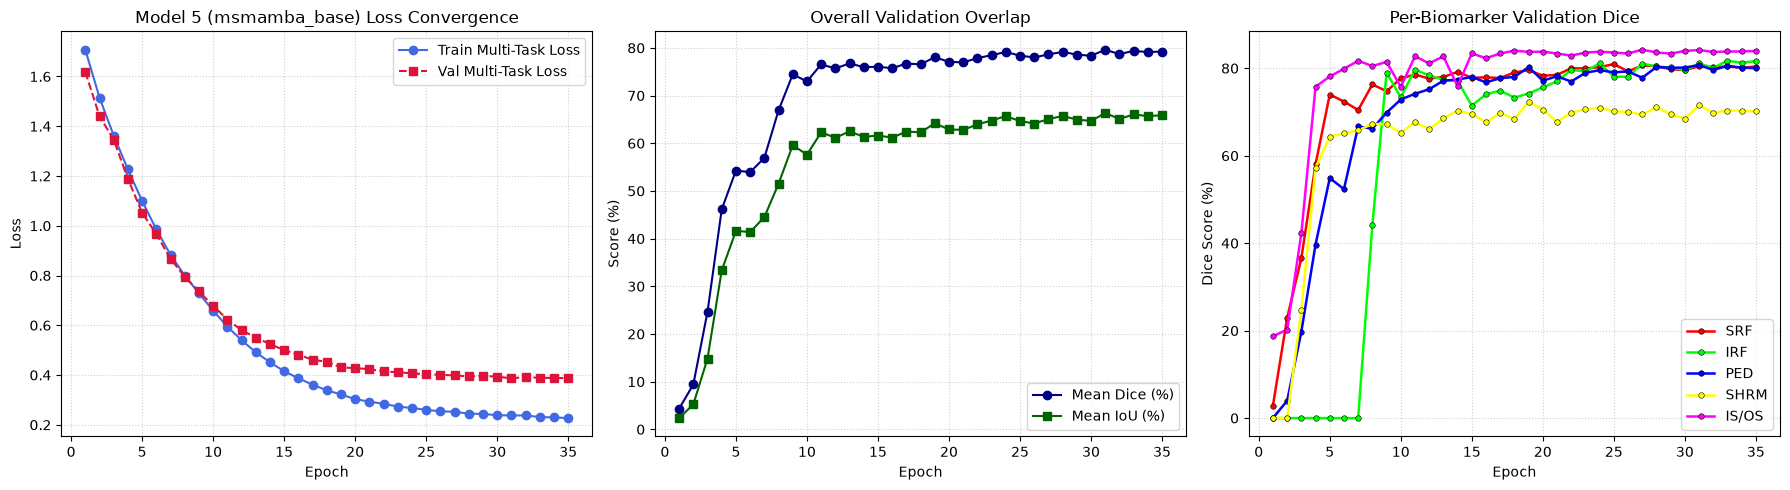

In [22]:
if os.path.exists(LOG_FILE):
    log_df = pd.read_csv(LOG_FILE)
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))

    axs[0].plot(log_df["epoch"], log_df["train_loss"], "o-", label="Train Multi-Task Loss", color="royalblue")
    axs[0].plot(log_df["epoch"], log_df["val_loss"], "s--", label="Val Multi-Task Loss", color="crimson")
    axs[0].set_title(f"Model 5 ({TAG}) Loss Convergence")
    axs[0].set_xlabel("Epoch"); axs[0].set_ylabel("Loss")
    axs[0].legend(); axs[0].grid(True, linestyle=":", alpha=0.6)

    axs[1].plot(log_df["epoch"], log_df["mean_dice"], "o-", label="Mean Dice (%)", color="navy")
    axs[1].plot(log_df["epoch"], log_df["mean_iou"], "s-", label="Mean IoU (%)", color="darkgreen")
    axs[1].set_title("Overall Validation Overlap")
    axs[1].set_xlabel("Epoch"); axs[1].set_ylabel("Score (%)")
    axs[1].legend(); axs[1].grid(True, linestyle=":", alpha=0.6)

    for lesion, pretty in zip(["SRF", "IRF", "PED", "SHRM", "IS_OS"], LESION_NAMES):
        axs[2].plot(
            log_df["epoch"], log_df[f"{lesion}_dice"], label=pretty, color=CLASS_COLORS_HEX[pretty],
            marker="o", markersize=4, markeredgecolor="black", markeredgewidth=0.4, linewidth=1.8
        )
    axs[2].set_title("Per-Biomarker Validation Dice")
    axs[2].set_xlabel("Epoch"); axs[2].set_ylabel("Dice Score (%)")
    axs[2].legend(); axs[2].grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.savefig(f"{SAVE_PREFIX}_training_curves.png", dpi=200)
    plt.show()
else:
    print(f"'{LOG_FILE}' not found - train the model first.")

## 7. Quantitative Model 5 (MSMamba) Benchmark Evaluation Report
Evaluates `best_unet_model5_<tag>.pth` across all 703 validation scans using pixel-pooled `GlobalMetricTracker` and compares against:
* **AMD-SD Paper U-Net Baseline** (Table 3 of Hu et al., *Scientific Data* 2024),
* **AMD-SD Paper ResUNet Baseline** (best model in Table 3 of Hu et al., *Scientific Data* 2024), and
* **Model 4 TransUNet (R50 + ViT-B/16)** from your previous experiment.

Loading Model 5 checkpoint: 'best_unet_model5_msmamba_base.pth'...


Evaluating Model 5 (MSMamba) Benchmark:   0%|          | 0/352 [00:00<?, ?it/s]


        WET AMD LESION SEGMENTATION: MODEL 5 (MSMAMBA_BASE) BENCHMARK REPORT (pixel-pooled, validation split)
    Biomarker / Class  Paper U-Net Dice (%)  Paper ResUNet Dice (%)  Model 4 TransUNet Dice (%)  Model 5 MSMamba Dice (%) Dice Δ vs U-Net Dice Δ vs ResUNet Dice Δ vs Model 4  Paper U-Net IoU (%)  Model 4 TransUNet IoU (%)  Model 5 MSMamba IoU (%) IoU Δ vs U-Net IoU Δ vs ResUNet
                  SRF                 78.65                   78.86                       81.05                     80.45           +1.80             +1.59             -0.60                64.81                      68.14                    67.29          +2.48            +2.18
                  IRF                 78.66                   81.16                       77.30                     81.11           +2.45             -0.05             +3.81                64.82                      63.00                    68.23          +3.41            -0.10
                  PED                 79.62         

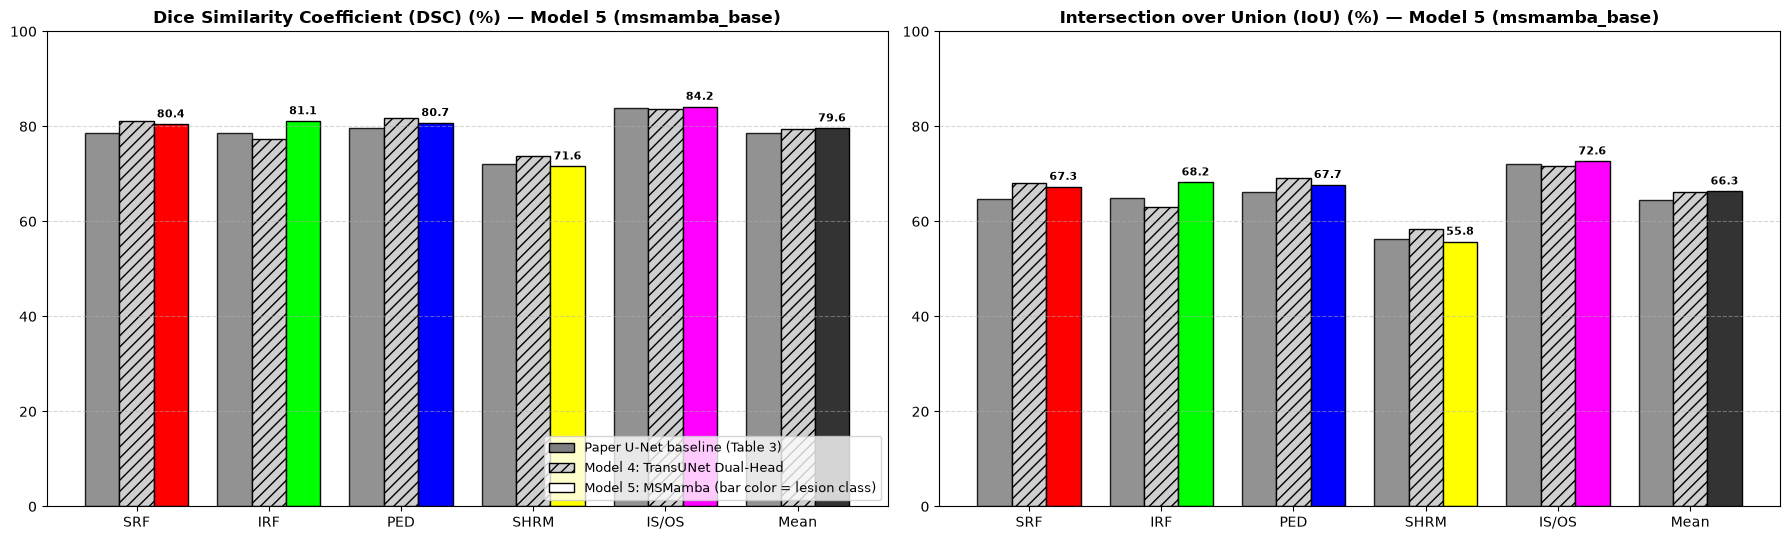

In [23]:
PAPER_UNET_DICE    = {"SRF": 78.65, "IRF": 78.66, "PED": 79.62, "SHRM": 72.04, "IS/OS": 83.76, "Mean": 78.55}
PAPER_UNET_IOU     = {"SRF": 64.81, "IRF": 64.82, "PED": 66.14, "SHRM": 56.37, "IS/OS": 72.06, "Mean": 64.48}
PAPER_RESUNET_DICE = {"SRF": 78.86, "IRF": 81.16, "PED": 81.88, "SHRM": 72.97, "IS/OS": 84.19, "Mean": 79.81}
PAPER_RESUNET_IOU  = {"SRF": 65.11, "IRF": 68.33, "PED": 69.33, "SHRM": 57.44, "IS/OS": 72.70, "Mean": 66.58}
MODEL4_TRANS_DICE  = {"SRF": 81.05, "IRF": 77.30, "PED": 81.81, "SHRM": 73.69, "IS/OS": 83.55, "Mean": 79.48}
MODEL4_TRANS_IOU   = {"SRF": 68.14, "IRF": 63.00, "PED": 69.22, "SHRM": 58.34, "IS/OS": 71.75, "Mean": 66.09}

def run_model5_benchmark():
    cleanup_memory()
    print(f"Loading Model 5 checkpoint: '{CKPT_PATH}'...")
    eval_model = load_model5(CKPT_PATH, variant=MODEL_VARIANT)
    tracker = GlobalMetricTracker(num_classes=NUM_CLASSES)

    with torch.no_grad():
        for images, mc_targets, _ in tqdm(val_loader, desc="Evaluating Model 5 (MSMamba) Benchmark"):
            images = images.to(device)
            mc_targets = mc_targets.to(device, dtype=torch.long)
            mc_logits, _ = eval_model(images)
            tracker.update(torch.argmax(mc_logits, dim=1), mc_targets)

    m_dice, m_iou, m_mean_dice, m_mean_iou = tracker.compute()
    m_dice["Mean"], m_iou["Mean"] = m_mean_dice, m_mean_iou

    rows = []
    for b in LESION_NAMES + ["Mean"]:
        rows.append({
            "Biomarker / Class": b if b != "Mean" else "Mean (All Biomarkers)",
            "Paper U-Net Dice (%)": PAPER_UNET_DICE[b],
            "Paper ResUNet Dice (%)": PAPER_RESUNET_DICE[b],
            "Model 4 TransUNet Dice (%)": MODEL4_TRANS_DICE[b],
            "Model 5 MSMamba Dice (%)": round(m_dice[b], 2),
            "Dice Δ vs U-Net": f"{m_dice[b] - PAPER_UNET_DICE[b]:+.2f}",
            "Dice Δ vs ResUNet": f"{m_dice[b] - PAPER_RESUNET_DICE[b]:+.2f}",
            "Dice Δ vs Model 4": f"{m_dice[b] - MODEL4_TRANS_DICE[b]:+.2f}",
            "Paper U-Net IoU (%)": PAPER_UNET_IOU[b],
            "Model 4 TransUNet IoU (%)": MODEL4_TRANS_IOU[b],
            "Model 5 MSMamba IoU (%)": round(m_iou[b], 2),
            "IoU Δ vs U-Net": f"{m_iou[b] - PAPER_UNET_IOU[b]:+.2f}",
            "IoU Δ vs ResUNet": f"{m_iou[b] - PAPER_RESUNET_IOU[b]:+.2f}",
        })
    benchmark_df = pd.DataFrame(rows)

    print("\n" + "=" * 125)
    print(f"        WET AMD LESION SEGMENTATION: MODEL 5 ({TAG.upper()}) BENCHMARK REPORT (pixel-pooled, validation split)")
    print("=" * 125)
    print(benchmark_df.to_string(index=False))
    out_csv = f"{SAVE_PREFIX}_benchmark_report.csv"
    benchmark_df.to_csv(out_csv, index=False)
    print(f"\nSaved report to '{out_csv}'.")

    # Visual bar chart comparison
    cats = LESION_NAMES + ["Mean"]
    x = np.arange(len(cats))
    w = 0.26
    fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
    for ax, metric, unet, trans, ours in zip(
        axes,
        ["Dice Similarity Coefficient (DSC) (%)", "Intersection over Union (IoU) (%)"],
        [PAPER_UNET_DICE, PAPER_UNET_IOU],
        [MODEL4_TRANS_DICE, MODEL4_TRANS_IOU],
        [m_dice, m_iou]
    ):
        ax.bar(x - w, [unet[c] for c in cats], w, color="#7f7f7f", alpha=0.85, edgecolor="black")
        ax.bar(x, [trans[c] for c in cats], w, color="#cfcfcf", hatch="///", edgecolor="black")
        rects = ax.bar(x + w, [ours[c] for c in cats], w, color=[PLOT_COLORS[c] for c in cats], edgecolor="black")
        ax.set_title(f"{metric} — Model 5 ({TAG})", fontweight="bold")
        ax.set_xticks(x); ax.set_xticklabels(cats)
        ax.set_ylim(0, 100); ax.grid(axis="y", linestyle="--", alpha=0.5)
        for bar in rects:
            ax.annotate(
                f"{bar.get_height():.1f}",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=8, fontweight="bold"
            )
    handles = [
        Patch(facecolor="#7f7f7f", edgecolor="black", label="Paper U-Net baseline (Table 3)"),
        Patch(facecolor="#cfcfcf", edgecolor="black", hatch="///", label="Model 4: TransUNet Dual-Head"),
        Patch(facecolor="white", edgecolor="black", label="Model 5: MSMamba (bar color = lesion class)"),
    ]
    axes[0].legend(handles=handles, loc="lower right", fontsize=9)
    plt.tight_layout()
    plt.savefig(f"{SAVE_PREFIX}_benchmark_bars.png", dpi=200)
    plt.show()

    del eval_model
    cleanup_memory()
    return benchmark_df

benchmark_df = run_model5_benchmark()

## 8. Qualitative Visualizations: Ground Truth vs. Multi-Class & Binary Predictions
Renders a **2 × 4 comparison grid** across representative validation B-scans containing multiple simultaneous wet AMD lesions:
1. **Input OCT B-Scan** ($512 \times 512$ grayscale)
2. **Expert Ground-Truth Mask** (colored by `CLASS_PALETTE_RGB`)
3. **Auxiliary Binary Lesion Probability Map** ($\sigma(\text{binary\_logits})$)
4. **Model 5 (MSMamba) Multi-Class Prediction**

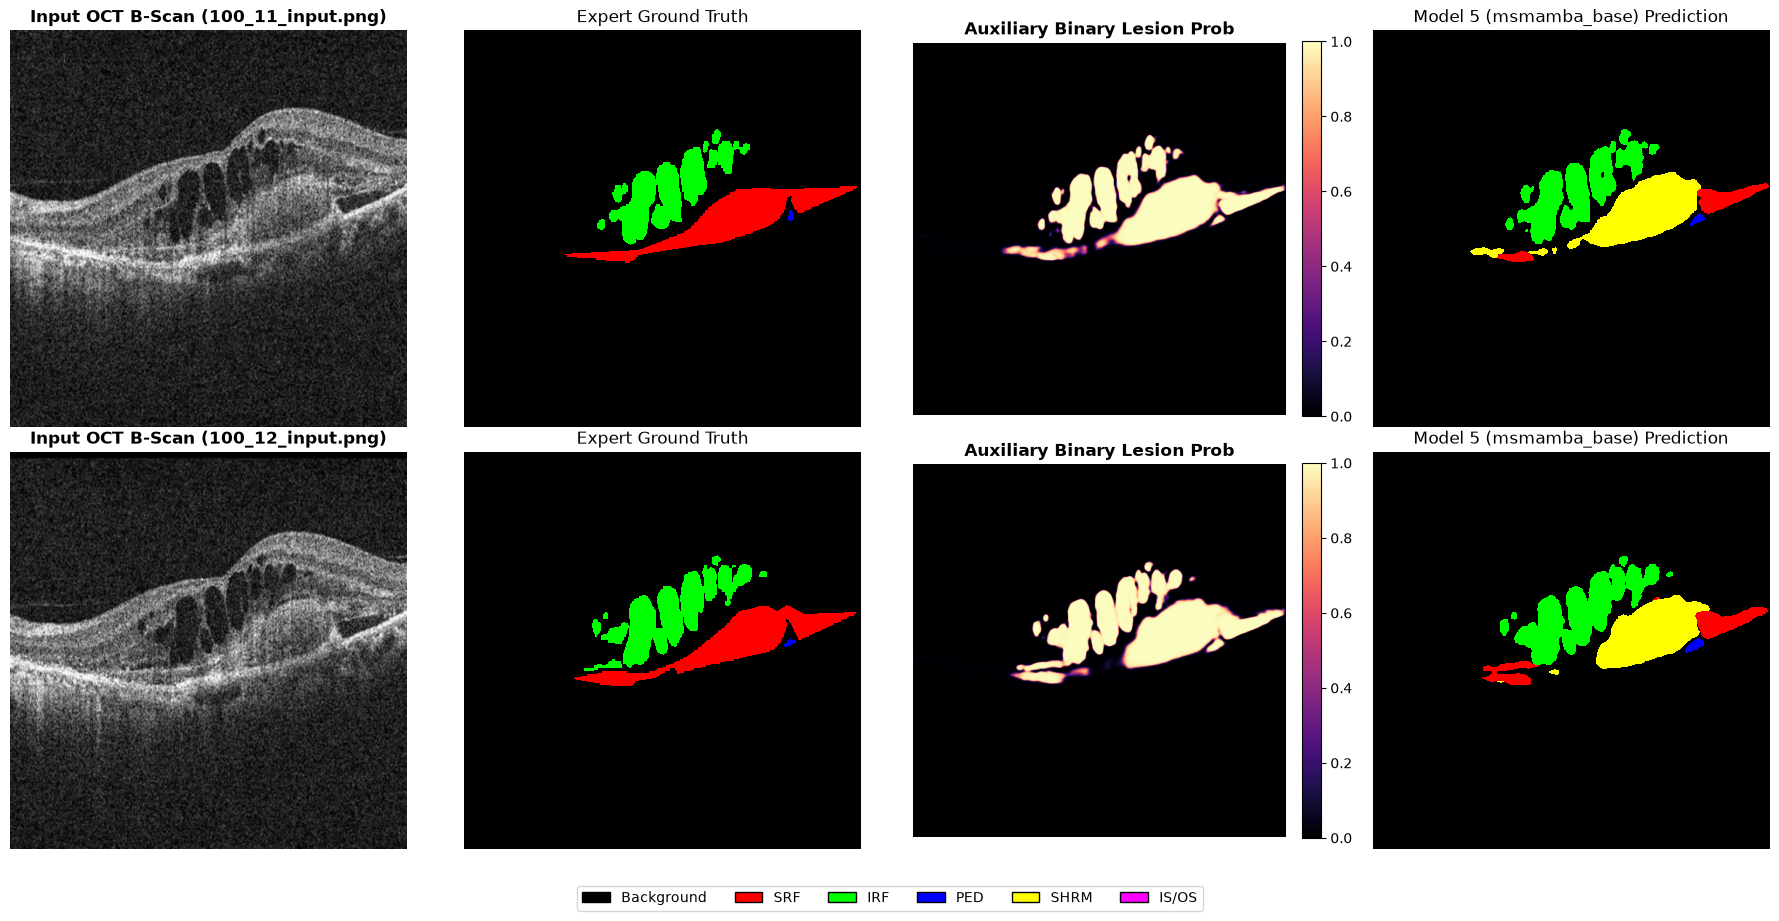

In [24]:
def visualize_model5_predictions(num_samples: int = 2):
    cleanup_memory()
    eval_model = load_model5(CKPT_PATH, variant=MODEL_VARIANT)

    # Select informative validation scans containing at least 3 distinct foreground lesion classes
    selected = []
    for idx in range(len(val_dataset)):
        img_t, mask_t, _ = val_dataset[idx]
        present_lesions = [c for c in range(1, NUM_CLASSES) if (mask_t == c).sum().item() > 80]
        if len(present_lesions) >= 3:
            selected.append((idx, img_t, mask_t))
        if len(selected) >= num_samples:
            break

    if len(selected) < num_samples:
        selected = [(i, *val_dataset[i][:2]) for i in range(num_samples)]

    fig, axes = plt.subplots(num_samples, 4, figsize=(18, 4.5 * num_samples))
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    with torch.no_grad():
        for row, (idx, img_t, mask_t) in enumerate(selected):
            fname = val_dataset.filenames[idx]
            inp = img_t.unsqueeze(0).to(device)
            mc_logits, bin_logits = eval_model(inp)

            pred_mask = torch.argmax(mc_logits, dim=1).squeeze(0).cpu().numpy()
            bin_prob  = torch.sigmoid(bin_logits).squeeze().cpu().numpy()
            img_np    = img_t.squeeze(0).numpy()
            gt_np     = mask_t.numpy()

            axes[row, 0].imshow(img_np, cmap="gray")
            axes[row, 0].set_title(f"Input OCT B-Scan ({fname})", fontweight="bold")
            axes[row, 0].axis("off")

            show_seg(axes[row, 1], gt_np, title="Expert Ground Truth")

            im_bin = axes[row, 2].imshow(bin_prob, cmap="magma", vmin=0.0, vmax=1.0)
            axes[row, 2].set_title("Auxiliary Binary Lesion Prob", fontweight="bold")
            axes[row, 2].axis("off")
            plt.colorbar(im_bin, ax=axes[row, 2], fraction=0.046, pad=0.04)

            show_seg(axes[row, 3], pred_mask, title=f"Model 5 ({TAG}) Prediction")

    fig.legend(
        handles=seg_legend_handles(include_background=True),
        loc="lower center", ncol=6, frameon=True, fontsize=10, bbox_to_anchor=(0.5, -0.02)
    )
    plt.tight_layout(rect=[0, 0.04, 1, 1])
    plt.savefig(f"{SAVE_PREFIX}_qualitative_grid.png", dpi=200, bbox_inches="tight")
    plt.show()

    del eval_model
    cleanup_memory()

visualize_model5_predictions(num_samples=2)

## 9. Statistical Evaluation: Per-Image Distributions, 99% Bootstrapped Confidence Intervals & Class-Coloured Plots

All per-image statistics are derived from one compact **raw data structure**: for every test slice, a $6 \times 6$ pixel confusion matrix (rows = ground truth, columns = prediction). From it we can recover, per class, the intersection, prediction size and ground-truth size, and therefore Dice / IoU under any scoring convention — without re-running the network. The confusion matrices are cached (`<model>_<split>_per_image_cm.npz`) and automatically invalidated if the checkpoint changes.

**Why the scoring convention matters (double-check of Models 1–3).** A B-scan often contains no pixels of a given class (e.g. no SHRM) in either the ground truth or the prediction. The earlier notebooks handled this *differently*:

| Convention | Slices where class is absent in **both** GT and prediction | Used by |
|---|---|---|
| `exclude` | dropped (`NaN`) | Model 2 |
| `credit` | scored as 100 % | Models 1 and 3 |
| `gt_present` | only slices whose **ground truth** contains the class are scored (false positives on GT-absent slices are ignored) | new — "how well is the class segmented *when it exists*" |

Because these slices are numerous, `credit` pushes means and the box position of rare classes upward, so Model 2 and Model 3 boxplots from the earlier notebooks are **not directly comparable**. Here `exclude` is the primary convention (it is the stricter of the two and matches Model 2); all three are computed, saved, and compared in §12.

**Plots (meeting note):**
* **Boxplot with the raw per-image points overlaid** (the actual value distribution; diamond = mean).
* **Confidence-interval plot**: mean ± 99 % bootstrap CI per class.
* Box / CI colours = the segmentation-mask colours of each class.

In [25]:
EVAL_CONVENTIONS = {
    "exclude":    "class absent in BOTH GT and prediction -> slice dropped (NaN)   [Model 2 convention]",
    "credit":     "class absent in BOTH GT and prediction -> slice scores 100%     [Model 1 / Model 3 convention]",
    "gt_present": "only slices whose GROUND TRUTH contains the class are scored",
}
PRIMARY_CONVENTION = "exclude"
PLOT_CLASSES = LESION_NAMES + ["Mean"]


def resolve_eval_split(preferred="test"):
    """Use the test split if it exists, otherwise fall back to val (with a loud warning)."""
    if os.path.exists(os.path.join(DATA_DIR, preferred, "inputs")):
        return preferred
    print(f"WARNING: '{os.path.join(DATA_DIR, preferred, 'inputs')}' not found -> falling back to the 'val' split. "
          f"Note that 'val' was used for checkpoint selection, so these numbers are optimistic.")
    return "val"


@torch.no_grad()
def collect_confusions(model, loader, mc_fn, num_classes=6, desc=""):
    """Per-image pixel confusion matrices cms[i, gt, pred] plus simple image statistics."""
    model.eval()
    cms, means, stds = [], [], []
    for images, targets, _ in tqdm(loader, desc=desc):
        images_d = images.to(device)
        preds = mc_fn(model(images_d)).argmax(dim=1).cpu()
        flat = images.flatten(1)
        means.append(flat.mean(dim=1).numpy()); stds.append(flat.std(dim=1).numpy())
        for b in range(preds.shape[0]):
            idx = targets[b].reshape(-1) * num_classes + preds[b].reshape(-1)
            cms.append(torch.bincount(idx, minlength=num_classes ** 2).reshape(num_classes, num_classes).numpy())
    return np.stack(cms).astype(np.int64), np.concatenate(means), np.concatenate(stds)


def get_per_image_cms(model_key, build_fn, ckpt_path, mc_fn, split, max_images=None, use_cache=True):
    """
    Returns (cms [N,6,6], meta DataFrame[dataset_idx, filename, img_mean, img_std]).
    Cached in '<model_key>_<split>[_n<max_images>]_per_image_cm.npz'; the cache is ignored if the checkpoint is newer.
    """
    suffix = f"_n{max_images}" if max_images else ""
    cache_path = f"{model_key}_{split}{suffix}_per_image_cm.npz"
    ckpt_mtime = os.path.getmtime(ckpt_path)

    if use_cache and os.path.exists(cache_path):
        z = np.load(cache_path)
        if float(z["ckpt_mtime"]) == ckpt_mtime:
            print(f"[cache] loaded per-image confusion matrices from '{cache_path}'")
            meta = pd.DataFrame({"dataset_idx": z["dataset_idx"], "filename": z["filenames"],
                                 "img_mean": z["img_mean"], "img_std": z["img_std"]})
            return z["cms"], meta
        print(f"[cache] '{cache_path}' is stale (checkpoint changed) -> recomputing")

    ds = AMDDatasetMSMamba(DATA_DIR, split=split, target_size=(IMG_SIZE, IMG_SIZE), augment=False)
    indices = np.arange(len(ds))
    if max_images and max_images < len(ds):
        indices = np.sort(np.random.default_rng(SEED).choice(len(ds), size=max_images, replace=False))
    loader = DataLoader(Subset(ds, indices.tolist()), batch_size=VAL_BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

    net = build_fn().to(device)
    net.load_state_dict(torch.load(ckpt_path, map_location=device))
    cms, img_mean, img_std = collect_confusions(net, loader, mc_fn, num_classes=NUM_CLASSES,
                                                desc=f"Evaluating {model_key} [{split}]")
    del net
    cleanup_memory()

    filenames = np.array([ds.filenames[i] for i in indices])
    np.savez_compressed(cache_path, cms=cms, dataset_idx=indices, filenames=filenames,
                        img_mean=img_mean, img_std=img_std, ckpt_mtime=ckpt_mtime)
    meta = pd.DataFrame({"dataset_idx": indices, "filename": filenames, "img_mean": img_mean, "img_std": img_std})
    return cms, meta


def per_image_metrics(cms, convention=PRIMARY_CONVENTION):
    """Per-image, per-class Dice / IoU (in %) from confusion matrices under a given scoring convention."""
    assert convention in EVAL_CONVENTIONS, f"unknown convention '{convention}'"
    out = {}
    for c, name in enumerate(LESION_NAMES, start=1):
        inter = cms[:, c, c].astype(np.float64)
        t_sum = cms[:, c, :].sum(axis=1).astype(np.float64)       # GT pixels of class c
        p_sum = cms[:, :, c].sum(axis=1).astype(np.float64)       # predicted pixels of class c
        union = t_sum + p_sum - inter
        denom = t_sum + p_sum
        dice = np.where(denom > 0, 2.0 * inter / np.maximum(denom, 1.0), np.nan) * 100.0
        iou = np.where(union > 0, inter / np.maximum(union, 1.0), np.nan) * 100.0
        both_empty = denom == 0
        if convention == "credit":
            dice[both_empty] = 100.0; iou[both_empty] = 100.0
        elif convention == "gt_present":
            dice[t_sum == 0] = np.nan; iou[t_sum == 0] = np.nan
        out[f"{name}_DSC"] = dice
        out[f"{name}_IoU"] = iou
    df = pd.DataFrame(out)
    df["Mean_DSC"] = df[[f"{n}_DSC" for n in LESION_NAMES]].mean(axis=1, skipna=True)
    df["Mean_IoU"] = df[[f"{n}_IoU" for n in LESION_NAMES]].mean(axis=1, skipna=True)
    return df


def bootstrap_ci(values, n_boot=2000, ci=0.99, seed=SEED, chunk=250):
    """Non-parametric percentile bootstrap CI of the mean. Returns (mean, lo, hi, n)."""
    v = np.asarray(values, dtype=np.float64)
    v = v[~np.isnan(v)]
    if v.size == 0:
        return np.nan, np.nan, np.nan, 0
    rng = np.random.default_rng(seed)
    means = np.empty(n_boot)
    for s in range(0, n_boot, chunk):
        e = min(n_boot, s + chunk)
        means[s:e] = v[rng.integers(0, v.size, size=(e - s, v.size))].mean(axis=1)
    a = (1.0 - ci) / 2.0 * 100.0
    return float(v.mean()), float(np.percentile(means, a)), float(np.percentile(means, 100.0 - a)), int(v.size)


def summarize_ci(df_metrics, n_boot=2000, ci=0.99):
    rows = []
    for metric_suffix, metric_name in [("DSC", "DSC"), ("IoU", "IoU")]:
        for c in PLOT_CLASSES:
            vals = df_metrics[f"{c}_{metric_suffix}"].to_numpy()
            mean, lo, hi, n = bootstrap_ci(vals, n_boot=n_boot, ci=ci)
            clean = vals[~np.isnan(vals)]
            rows.append({
                "Class": c, "Metric": metric_name, "N slices": n,
                "Mean (%)": round(mean, 2), "Median (%)": round(float(np.median(clean)), 2) if n else np.nan,
                "Std (%)": round(float(clean.std(ddof=1)), 2) if n > 1 else np.nan,
                f"{int(ci * 100)}% CI Lower": round(lo, 2), f"{int(ci * 100)}% CI Upper": round(hi, 2),
            })
    return pd.DataFrame(rows)


# ------------------------------------- plotting -------------------------------------
def plot_boxplots_raw(df_metrics, title, save_path=None, show_raw=True):
    """Per-class boxplots (class colours) with the raw per-image values overlaid; diamond = mean."""
    fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
    rng = np.random.default_rng(0)
    for ax, (suffix, label) in zip(axes, [("DSC", "Dice Similarity Coefficient (DSC)"), ("IoU", "Intersection over Union (IoU)")]):
        data = [df_metrics[f"{c}_{suffix}"].dropna().to_numpy() for c in PLOT_CLASSES]
        bp = ax.boxplot(
            data, positions=np.arange(1, len(data) + 1), patch_artist=True, widths=0.55, showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 7},
            medianprops={"color": "black", "linewidth": 2},
            flierprops={"marker": "" if show_raw else "o", "markersize": 3, "alpha": 0.35},
        )
        for patch, c in zip(bp["boxes"], PLOT_CLASSES):
            patch.set_facecolor(to_rgba(PLOT_COLORS[c], 0.55)); patch.set_edgecolor("black"); patch.set_linewidth(1.3)
        if show_raw:
            for i, vals in enumerate(data, start=1):
                ax.scatter(i + rng.uniform(-0.22, 0.22, size=len(vals)), vals, s=7, color="black", alpha=0.17, linewidths=0, zorder=3)
        ax.set_xticks(np.arange(1, len(data) + 1))
        ax.set_xticklabels([f"{c}\n(n={len(d)})" for c, d in zip(PLOT_CLASSES, data)])
        ax.set_title(f"{title}\n{label} per image", fontsize=12, fontweight="bold")
        ax.set_ylabel(f"{label} (%)"); ax.set_xlabel("Biomarker (box colour = class colour in segmentation maps)")
        ax.set_ylim(-3, 106); ax.grid(axis="y", linestyle="--", alpha=0.6)
        for i, vals in enumerate(data, start=1):
            if len(vals):
                ax.text(i, 102.5, f"{vals.mean():.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=250)
    plt.show()


def plot_ci_estimates(df_ci, title, save_path=None):
    """Mean with 99% bootstrap CI per class, coloured like the segmentation classes."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    ci_lo_col = [c for c in df_ci.columns if c.endswith("CI Lower")][0]
    ci_hi_col = [c for c in df_ci.columns if c.endswith("CI Upper")][0]
    ci_label = ci_lo_col.replace(" CI Lower", "")
    for ax, metric in zip(axes, ["DSC", "IoU"]):
        sub = df_ci[df_ci["Metric"] == metric].set_index("Class").loc[PLOT_CLASSES]
        for i, c in enumerate(PLOT_CLASSES):
            m, lo, hi = sub.loc[c, "Mean (%)"], sub.loc[c, ci_lo_col], sub.loc[c, ci_hi_col]
            yerr = [[m - lo], [hi - m]]
            ax.errorbar(i, m, yerr=yerr, fmt="none", ecolor="black", elinewidth=6, capsize=9, capthick=3, zorder=2)   # outline
            ax.errorbar(i, m, yerr=yerr, fmt="o", color=PLOT_COLORS[c], ecolor=PLOT_COLORS[c], elinewidth=3.5, capsize=7,
                        capthick=2, markersize=11, markeredgecolor="black", markeredgewidth=1.2, zorder=3)
            ax.annotate(f"{m:.1f}\n[{lo:.1f}, {hi:.1f}]", (i, hi), xytext=(0, 8), textcoords="offset points",
                        ha="center", va="bottom", fontsize=9)
        ax.set_xticks(range(len(PLOT_CLASSES)))
        ax.set_xticklabels([f"{c}\n(n={int(sub.loc[c, 'N slices'])})" for c in PLOT_CLASSES])
        lo_all, hi_all = sub[ci_lo_col].min(), sub[ci_hi_col].max()
        pad = max(4.0, 0.15 * (hi_all - lo_all))
        ax.set_ylim(max(0, lo_all - pad), min(100, hi_all + pad + 6))
        ax.set_xlim(-0.6, len(PLOT_CLASSES) - 0.4)
        ax.set_ylabel(f"Mean {metric} (%)"); ax.set_xlabel("Biomarker")
        ax.set_title(f"{title}\nMean {metric} with {ci_label} bootstrap CI", fontsize=12, fontweight="bold")
        ax.grid(axis="y", linestyle="--", alpha=0.6)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=250)
    plt.show()

Evaluating Model 5 (msmamba_base) on split 'val'...


Evaluating model5_msmamba_base [val]:   0%|          | 0/352 [00:00<?, ?it/s]

Saved raw per-image pixel counts to 'model5_msmamba_base_val_per_image_raw_counts.csv'.

  MODEL 4 (msmamba_base) — 99% BOOTSTRAPPED CIs (2000 resamples) | split='val' | convention='exclude'
Class Metric  N slices  Mean (%)  Median (%)  Std (%)  99% CI Lower  99% CI Upper
  SRF    DSC       489     60.40       77.70    36.76         56.39         64.70
  IRF    DSC       233     44.01       53.72    40.12         37.04         51.08
  PED    DSC       528     54.13       71.58    37.02         50.12         58.32
 SHRM    DSC       488     49.51       62.67    37.05         45.05         54.03
IS/OS    DSC       648     73.11       84.77    28.25         70.23         75.93
 Mean    DSC       703     61.33       61.86    21.93         59.17         63.49
  SRF    IoU       489     52.30       63.53    34.83         48.49         56.44
  IRF    IoU       233     37.27       36.73    35.62         31.22         43.53
  PED    IoU       528     45.56       55.74    33.73         41.87    

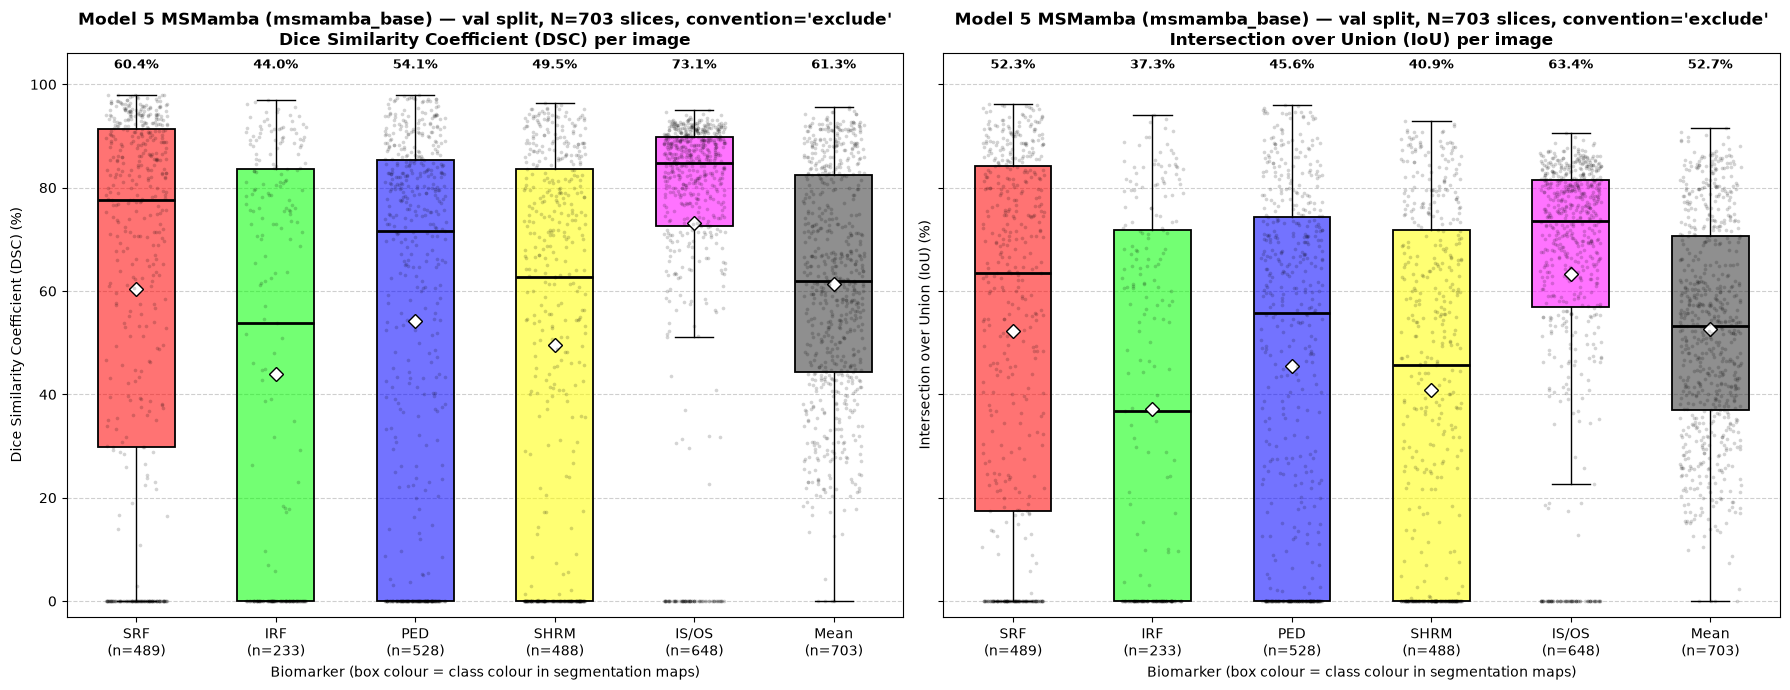

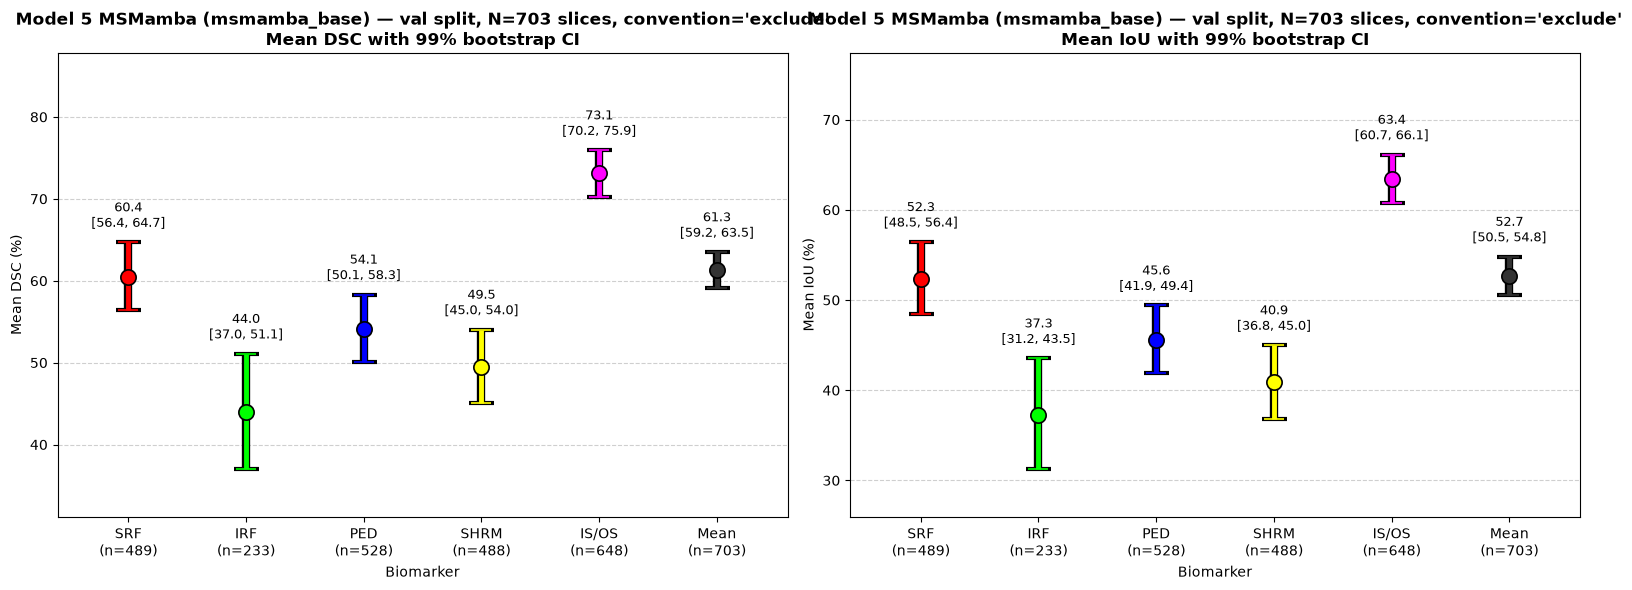

In [26]:
def run_model5_statistical_eval(split_pref="test", n_boot=2000):
    split = resolve_eval_split(split_pref)
    print(f"Evaluating Model 5 ({TAG}) on split '{split}'...")
    cms, meta = get_per_image_cms(MODEL_KEY, lambda: MSMambaDualHead(in_channels=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, variant=MODEL_VARIANT),
                                  CKPT_PATH, lambda out: out[0], split)

    # ---- Raw data export: per-image, per-class pixel counts (GT size, prediction size, intersection) ----
    raw = meta.copy()
    for c, name in enumerate(LESION_NAMES, start=1):
        raw[f"{name}_GT_px"] = cms[:, c, :].sum(axis=1)
        raw[f"{name}_Pred_px"] = cms[:, :, c].sum(axis=1)
        raw[f"{name}_Inter_px"] = cms[:, c, c]
    raw_csv = f"{SAVE_PREFIX}_{split}_per_image_raw_counts.csv"
    raw.to_csv(raw_csv, index=False)
    print(f"Saved raw per-image pixel counts to '{raw_csv}'.")

    # ---- Per-image metrics under every convention, saved to disk ----
    metrics = {}
    for conv in EVAL_CONVENTIONS:
        df_m = per_image_metrics(cms, conv)
        metrics[conv] = df_m
        out = pd.concat([meta[["filename"]], df_m], axis=1)
        out.to_csv(f"{SAVE_PREFIX}_{split}_per_image_scores_{conv}.csv", index=False)

    # ---- Primary convention: CI table + plots ----
    df_ci = summarize_ci(metrics[PRIMARY_CONVENTION], n_boot=n_boot)
    ci_csv = f"{SAVE_PREFIX}_{split}_bootstrapped_99_ci_{PRIMARY_CONVENTION}.csv"
    df_ci.to_csv(ci_csv, index=False)
    print("\n" + "=" * 100)
    print(f"  MODEL 4 ({TAG}) — 99% BOOTSTRAPPED CIs ({n_boot} resamples) | split='{split}' | convention='{PRIMARY_CONVENTION}'")
    print("=" * 100)
    print(df_ci.to_string(index=False))
    print(f"\nSaved to '{ci_csv}'.")

    # ---- How much does the convention change the answer? (mean DSC) ----
    gap = pd.DataFrame({conv: {c: np.nanmean(metrics[conv][f"{c}_DSC"].to_numpy()) for c in PLOT_CLASSES}
                        for conv in EVAL_CONVENTIONS}).round(2)
    gap["credit − exclude"] = (gap["credit"] - gap["exclude"]).round(2)
    print("\nMean DSC (%) per class under each scoring convention:")
    print(gap.to_string())

    title = f"Model 5 MSMamba ({TAG}) — {split} split, N={len(cms)} slices, convention='{PRIMARY_CONVENTION}'"
    plot_boxplots_raw(metrics[PRIMARY_CONVENTION], title, save_path=f"{SAVE_PREFIX}_{split}_boxplots_raw.png")
    plot_ci_estimates(df_ci, title, save_path=f"{SAVE_PREFIX}_{split}_ci_plot.png")
    return cms, meta, split

M5_CMS, M5_META, M5_SPLIT = run_model5_statistical_eval(split_pref="test", n_boot=2000)

## 10. Pixel-Level Confusion Matrix
Every pixel of every evaluation slice is one observation (rows = ground truth, columns = prediction), aggregated from the per-image confusion matrices computed in §9.

* **Left:** the full $6 \times 6$ matrix including *Background*, row-normalised (each row sums to 100 % → per-class recall on the diagonal). Background is kept because most lesion errors are "lesion ↔ background" mistakes and would otherwise be invisible.
* **Right:** the **5-class lesion-only** matrix: only ground-truth lesion pixels that the network *also* labelled as some lesion class, re-normalised per row. This isolates **which lesion classes get mistaken for each other**, once "missed entirely" is factored out.

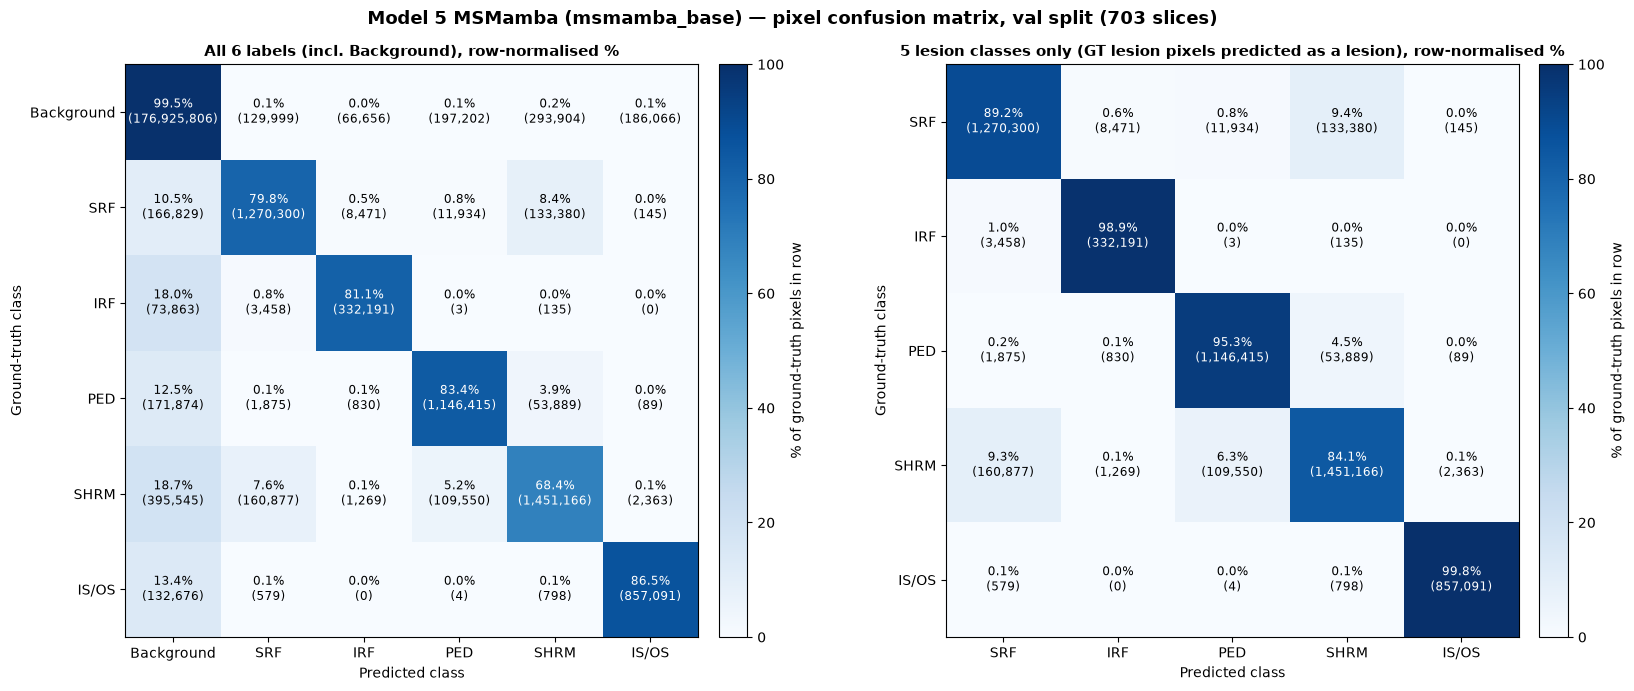


Top-8 confusions (share of the ground-truth class labelled as the other class):
  GT SHRM       -> predicted Background:  18.65%
  GT IRF        -> predicted Background:  18.03%
  GT IS/OS      -> predicted Background:  13.39%
  GT PED        -> predicted Background:  12.50%
  GT SRF        -> predicted Background:  10.49%
  GT SRF        -> predicted SHRM      :   8.38%
  GT SHRM       -> predicted SRF       :   7.59%
  GT SHRM       -> predicted PED       :   5.17%


In [27]:
def plot_confusion_matrix(cm, title, save_path=None):
    n6 = cm.astype(np.float64)
    row6 = n6.sum(axis=1, keepdims=True)
    norm6 = np.divide(n6, row6, out=np.zeros_like(n6), where=row6 > 0) * 100.0

    cm5 = n6[1:, 1:]
    row5 = cm5.sum(axis=1, keepdims=True)
    norm5 = np.divide(cm5, row5, out=np.zeros_like(cm5), where=row5 > 0) * 100.0

    fig, axes = plt.subplots(1, 2, figsize=(17, 7))
    panels = [
        (axes[0], norm6, n6, CLASS_NAMES, "All 6 labels (incl. Background), row-normalised %"),
        (axes[1], norm5, cm5, LESION_NAMES, "5 lesion classes only (GT lesion pixels predicted as a lesion), row-normalised %"),
    ]
    for ax, norm, counts, names, sub in panels:
        im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=100)
        for i in range(len(names)):
            for j in range(len(names)):
                col = "white" if norm[i, j] > 55 else "black"
                ax.text(j, i, f"{norm[i, j]:.1f}%\n({int(counts[i, j]):,})", ha="center", va="center", color=col, fontsize=8.5)
        ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
        ax.set_xticklabels(names); ax.set_yticklabels(names)
        ax.set_xlabel("Predicted class"); ax.set_ylabel("Ground-truth class")
        ax.set_title(sub, fontsize=11, fontweight="bold")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="% of ground-truth pixels in row")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=250)
    plt.show()
    return norm6, norm5


cm_total = M5_CMS.sum(axis=0)
norm6, norm5 = plot_confusion_matrix(
    cm_total, f"Model 5 MSMamba ({TAG}) — pixel confusion matrix, {M5_SPLIT} split ({len(M5_CMS)} slices)",
    save_path=f"{SAVE_PREFIX}_{M5_SPLIT}_confusion_matrix.png")

pd.DataFrame(cm_total, index=[f"GT:{n}" for n in CLASS_NAMES], columns=[f"Pred:{n}" for n in CLASS_NAMES]) \
  .to_csv(f"{SAVE_PREFIX}_{M5_SPLIT}_confusion_matrix_counts.csv")

# Most frequent mistakes, as a fraction of each ground-truth class
conf = pd.DataFrame(norm6, index=CLASS_NAMES, columns=CLASS_NAMES)
pairs = [(g, p, conf.loc[g, p]) for g in CLASS_NAMES for p in CLASS_NAMES if g != p]
print("\nTop-8 confusions (share of the ground-truth class labelled as the other class):")
for g, p, v in sorted(pairs, key=lambda t: -t[2])[:8]:
    print(f"  GT {g:<10} -> predicted {p:<10}: {v:6.2f}%")

## 11. Error Analysis: Low-Dice / Low-IoU Examples from the TRAIN or VAL Set
As suggested in the meeting, we look at the *worst* slices on **train or validation data — never the test set** — to see whether there are visible reasons for poor performance, without tuning on the test set.

For the chosen split the cell:
1. Ranks slices by Dice over the lesion classes present in the ground truth (or by a single `focus_class`).
2. Plots the worst `k` slices as **Input / Ground truth / Prediction / Error map**. The error map uses colours that are *not* in the class palette, so they cannot be confused with lesion classes: orange = lesion missed (predicted background), white = false alarm (predicted lesion on background), cyan = wrong lesion class, dark grey = correct.
3. Tests simple hypotheses with Spearman correlations and plots: is Dice driven by lesion size, number of classes present, or image brightness / contrast?

Use `split="train"` with `max_images=800` to run the same analysis on a random subset of the training data. A big train/val gap in these statistics points to over-fitting rather than data difficulty.

[cache] loaded per-image confusion matrices from 'model5_msmamba_base_val_per_image_cm.npz'
[val] 703/703 slices have the scored class(es) present in the ground truth.

Worst 6 slices by Mean Dice:
 dataset_idx         filename GT_classes  GT_lesion_px  Pred_lesion_px  Mean Dice (%)  Mean IoU (%)  img_mean  img_std  Pred/GT area
         117  104_6_input.png       SHRM           879             887           0.00          0.00      0.22     0.17          1.01
         144  105_3_input.png        PED           224              42           0.00          0.00      0.20     0.17          0.19
         145  105_4_input.png        PED           115             320           0.00          0.00      0.20     0.17          2.78
         146  105_5_input.png        SRF           153             245           0.00          0.00      0.20     0.17          1.60
         484 120_11_input.png       SHRM          9300            6482          17.31          9.47      0.19     0.13          0.70
    

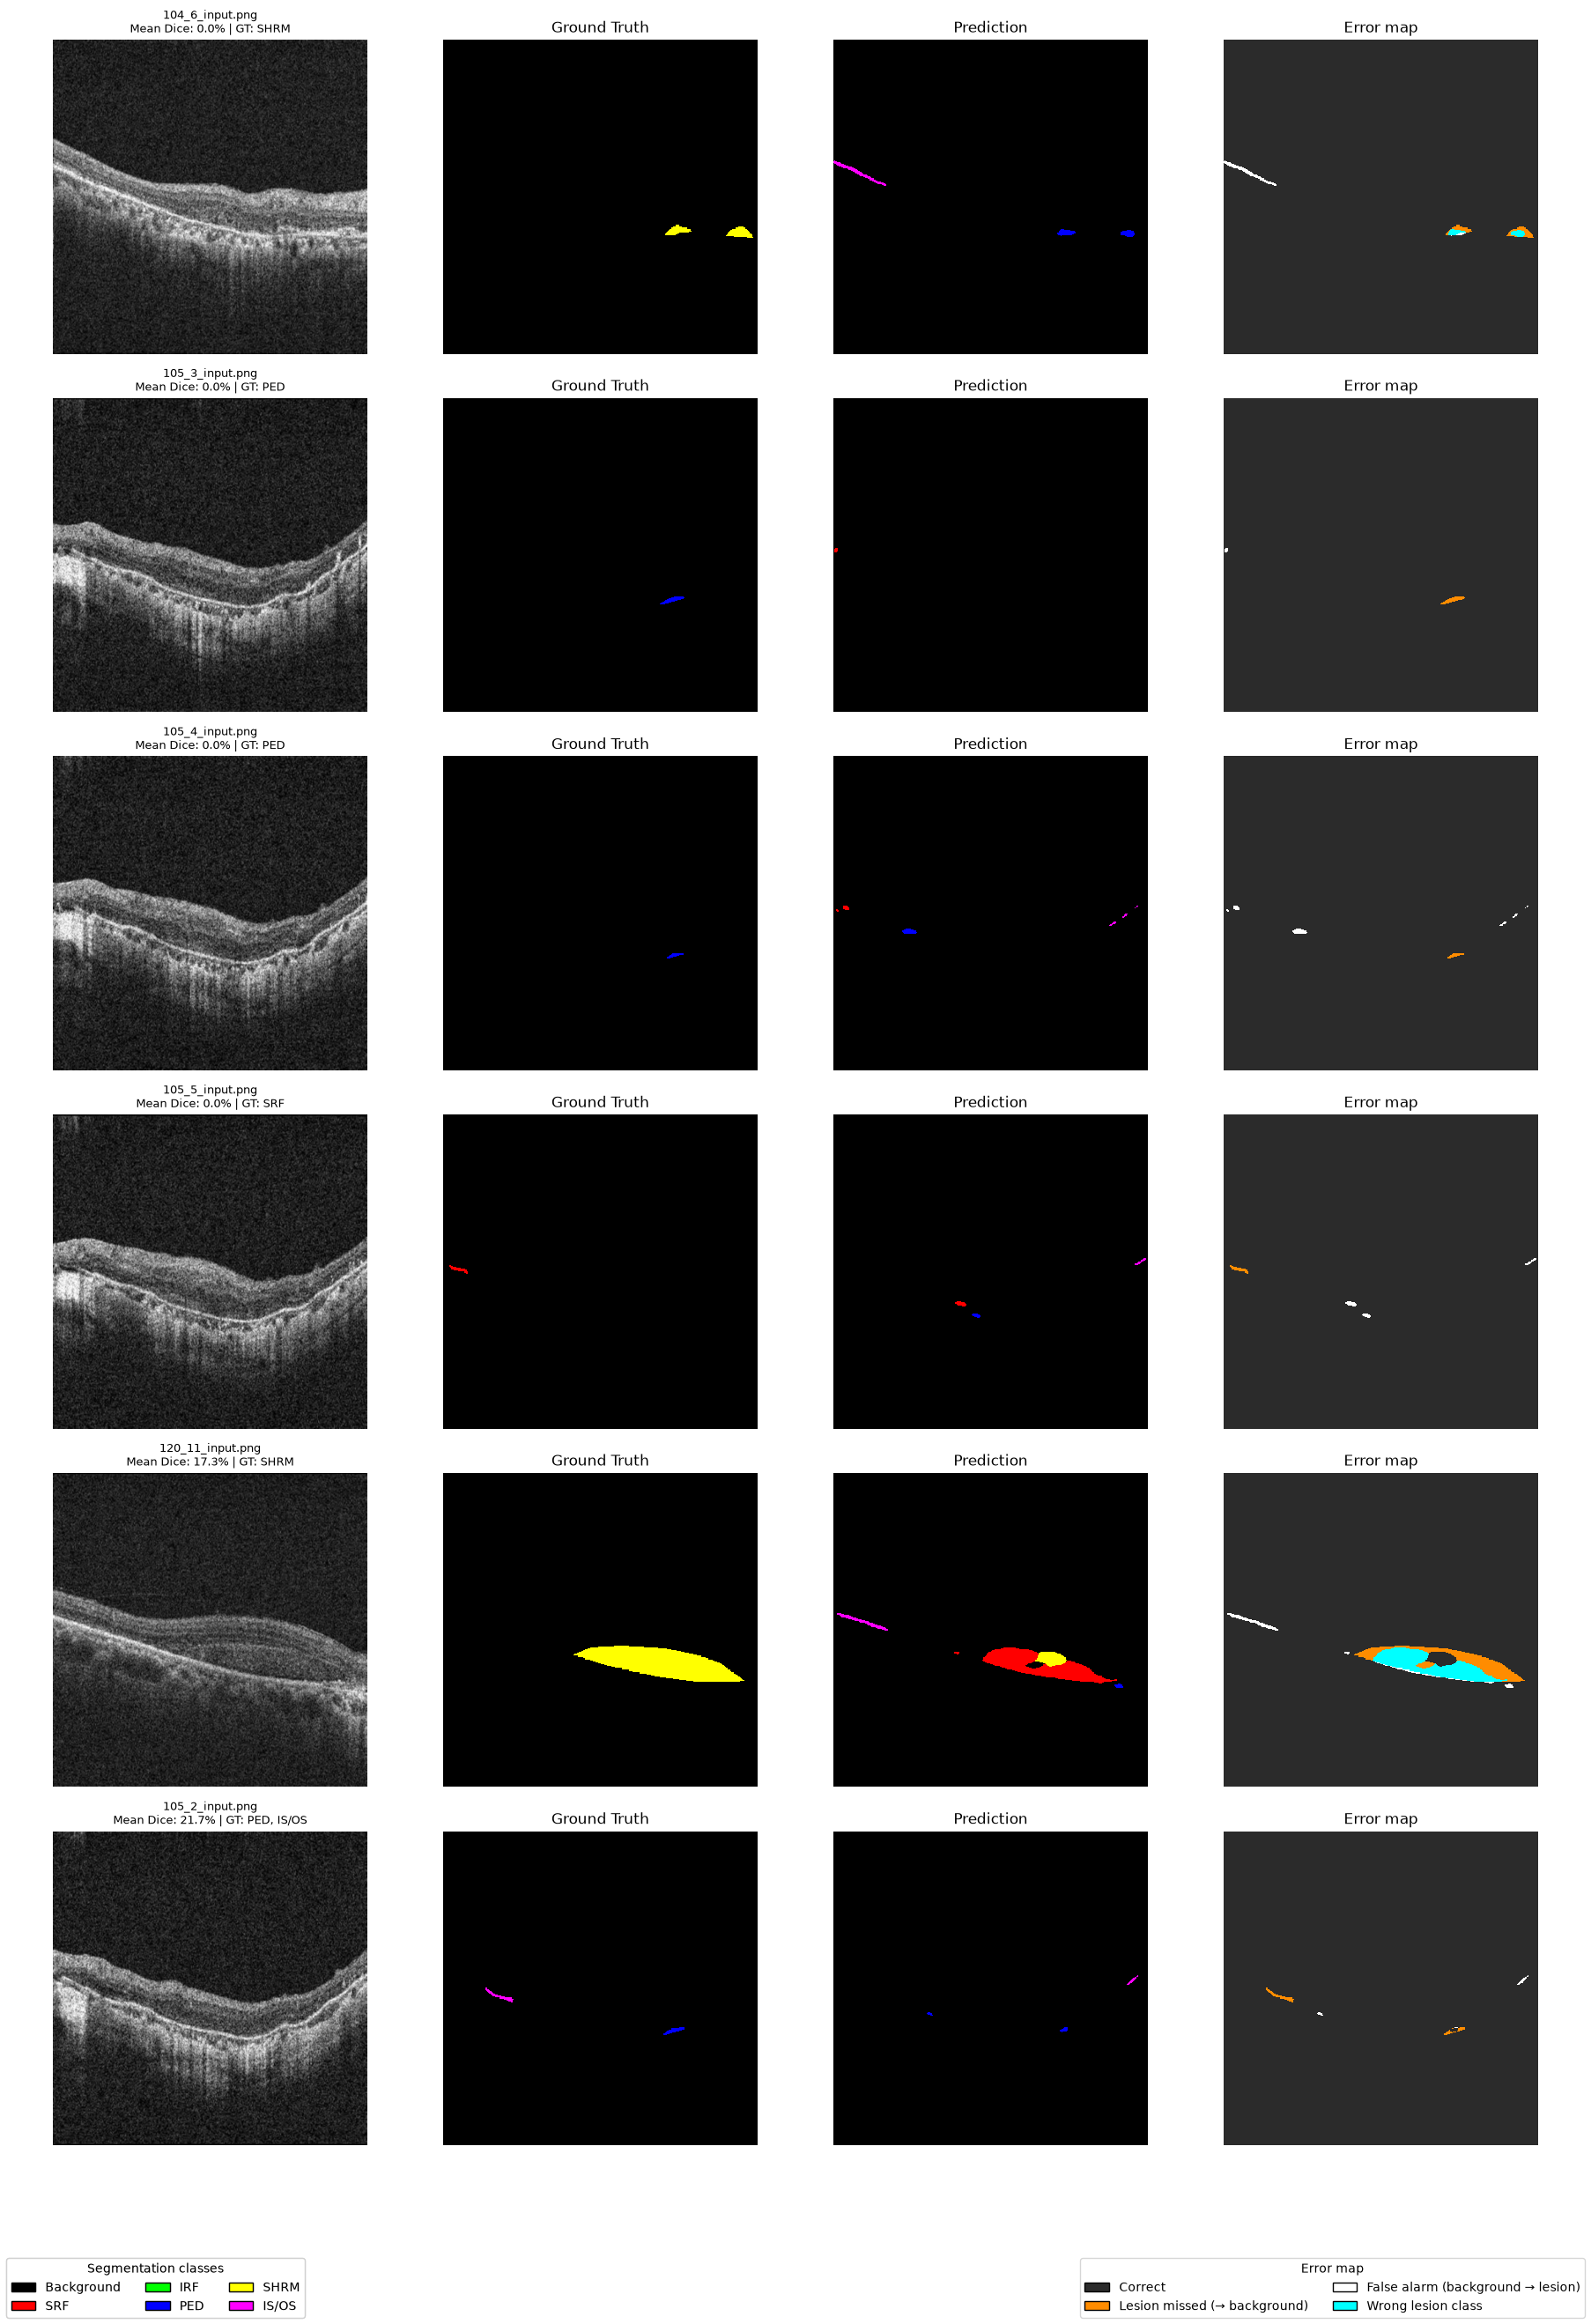


Spearman correlation of Mean Dice with candidate explanatory variables (val, scored slices only):
log10(GT lesion area in px)    0.104
# lesion classes in GT        -0.227
image mean intensity          -0.058
image contrast (std)          -0.073


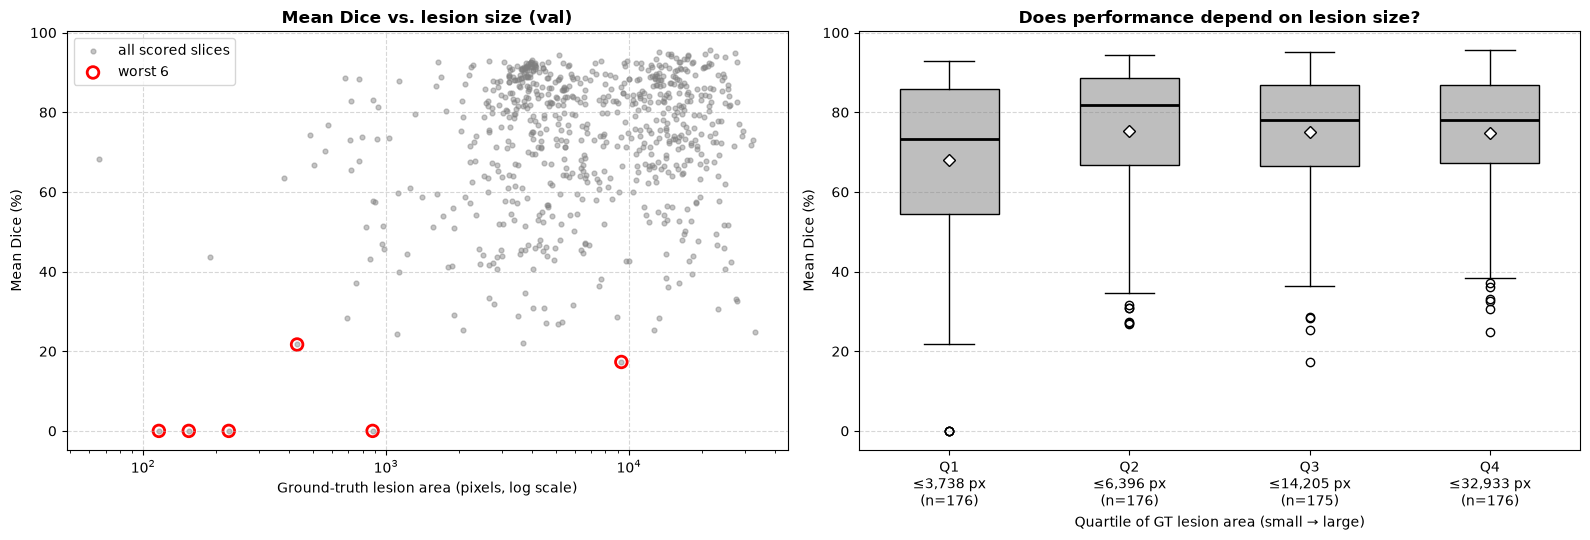

In [28]:
ERR_NAMES  = ["Correct", "Lesion missed (→ background)", "False alarm (background → lesion)", "Wrong lesion class"]
ERR_COLORS = ["#2b2b2b", "#ff8c00", "#ffffff", "#00ffff"]
ERR_CMAP = ListedColormap(ERR_COLORS)


def error_map(gt, pred):
    err = np.zeros_like(gt)
    err[(gt > 0) & (pred == 0)] = 1
    err[(gt == 0) & (pred > 0)] = 2
    err[(gt > 0) & (pred > 0) & (gt != pred)] = 3
    return err


def analyze_low_performers(split="val", k=6, focus_class=None, max_images=None):
    assert split in ("train", "val"), "Error analysis should use TRAIN or VAL data, not the test set."
    cms, meta = get_per_image_cms(MODEL_KEY, lambda: MSMambaDualHead(in_channels=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, variant=MODEL_VARIANT),
                                  CKPT_PATH, lambda out: out[0], split, max_images=max_images)
    dfm = per_image_metrics(cms, "gt_present")
    score_col = "Mean_DSC" if focus_class is None else f"{focus_class}_DSC"

    gt_px, pred_px = cms.sum(axis=2), cms.sum(axis=1)       # (N, 6): GT pixels / predicted pixels per class
    info = meta.copy()
    info["score"] = dfm[score_col].to_numpy()
    info["Mean_IoU"] = dfm["Mean_IoU"].to_numpy()
    info["GT_lesion_px"] = gt_px[:, 1:].sum(axis=1)
    info["Pred_lesion_px"] = pred_px[:, 1:].sum(axis=1)
    info["n_GT_classes"] = (gt_px[:, 1:] > 0).sum(axis=1)
    info["GT_classes"] = [", ".join(n for n, c in zip(LESION_NAMES, range(1, 6)) if gt_px[i, c] > 0) or "-" for i in range(len(info))]
    info["log10_GT_px"] = np.log10(info["GT_lesion_px"] + 1)
    elig = info[info["score"].notna()].copy()
    worst = elig.nsmallest(k, "score")

    label = "Mean Dice" if focus_class is None else f"{focus_class} Dice"
    print(f"[{split}] {len(elig)}/{len(info)} slices have the scored class(es) present in the ground truth.")
    print(f"\nWorst {len(worst)} slices by {label}:")
    show = worst[["dataset_idx", "filename", "GT_classes", "GT_lesion_px", "Pred_lesion_px", "score", "Mean_IoU", "img_mean", "img_std"]].copy()
    show["Pred/GT area"] = (show["Pred_lesion_px"] / show["GT_lesion_px"].clip(lower=1)).round(2)
    show = show.rename(columns={"score": label + " (%)", "Mean_IoU": "Mean IoU (%)"}).round(2)
    print(show.to_string(index=False))

    # ---------------- Visual inspection of the worst slices ----------------
    ds = AMDDatasetMSMamba(DATA_DIR, split=split, target_size=(IMG_SIZE, IMG_SIZE), augment=False)
    net = load_model5(CKPT_PATH, variant=MODEL_VARIANT)
    rows = list(worst.itertuples())
    fig, axs = plt.subplots(len(rows), 4, figsize=(18, 4.4 * len(rows)), squeeze=False)
    for r, row in enumerate(rows):
        img, gt, _ = ds[int(row.dataset_idx)]
        with torch.no_grad():
            pred = net(img.unsqueeze(0).to(device))[0].argmax(dim=1)[0].cpu().numpy()
        gt_np = gt.numpy()
        axs[r, 0].imshow(img[0].numpy(), cmap="gray"); axs[r, 0].axis("off")
        axs[r, 0].set_title(f"{row.filename}\n{label}: {row.score:.1f}% | GT: {row.GT_classes}", fontsize=9)
        show_seg(axs[r, 1], gt_np, "Ground Truth")
        show_seg(axs[r, 2], pred, "Prediction")
        axs[r, 3].imshow(error_map(gt_np, pred), cmap=ERR_CMAP, vmin=0, vmax=3, interpolation="nearest")
        axs[r, 3].set_title("Error map"); axs[r, 3].axis("off")
    leg1 = fig.legend(handles=seg_legend_handles(), loc="lower left", ncol=3, title="Segmentation classes", frameon=True)
    fig.add_artist(leg1)
    fig.legend(handles=[Patch(facecolor=c, edgecolor="black", label=n) for c, n in zip(ERR_COLORS, ERR_NAMES)],
               loc="lower right", ncol=2, title="Error map", frameon=True)
    plt.tight_layout(rect=[0, 0.07, 1, 1])
    plt.savefig(f"{SAVE_PREFIX}_{split}_worst_examples.png", dpi=200)
    plt.show()
    del net
    cleanup_memory()

    # ---------------- Hypothesis checks ----------------
    corr = elig[["score", "log10_GT_px", "n_GT_classes", "img_mean", "img_std"]].corr(method="spearman")["score"].drop("score")
    print(f"\nSpearman correlation of {label} with candidate explanatory variables ({split}, scored slices only):")
    print(corr.rename({"log10_GT_px": "log10(GT lesion area in px)", "n_GT_classes": "# lesion classes in GT",
                       "img_mean": "image mean intensity", "img_std": "image contrast (std)"}).round(3).to_string())

    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    axes[0].scatter(elig["GT_lesion_px"] + 1, elig["score"], s=12, color="#7f7f7f", alpha=0.45, label="all scored slices")
    axes[0].scatter(worst["GT_lesion_px"] + 1, worst["score"], s=70, facecolors="none", edgecolors="red", linewidths=2, label=f"worst {len(worst)}")
    axes[0].set_xscale("log")
    axes[0].set_xlabel("Ground-truth lesion area (pixels, log scale)"); axes[0].set_ylabel(f"{label} (%)")
    axes[0].set_title(f"{label} vs. lesion size ({split})", fontweight="bold")
    axes[0].grid(True, linestyle="--", alpha=0.5); axes[0].legend()

    bins = pd.qcut(elig["GT_lesion_px"], q=4, duplicates="drop")
    groups = [elig.loc[bins == b, "score"].to_numpy() for b in bins.cat.categories]
    bp = axes[1].boxplot(groups, patch_artist=True, showmeans=True, widths=0.55,
                         meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"},
                         medianprops={"color": "black", "linewidth": 2})
    for patch in bp["boxes"]:
        patch.set_facecolor(to_rgba("#7f7f7f", 0.5)); patch.set_edgecolor("black")
    axes[1].set_xticklabels([f"Q{i + 1}\n≤{int(b.right):,} px\n(n={len(g)})" for i, (b, g) in enumerate(zip(bins.cat.categories, groups))])
    axes[1].set_xlabel("Quartile of GT lesion area (small → large)"); axes[1].set_ylabel(f"{label} (%)")
    axes[1].set_title("Does performance depend on lesion size?", fontweight="bold")
    axes[1].grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(f"{SAVE_PREFIX}_{split}_lowdice_diagnostics.png", dpi=200)
    plt.show()
    return info

# Validation slices (default). Examples of other uses:
#   analyze_low_performers(split="train", k=6, max_images=800)    # same analysis on a random training subset
#   analyze_low_performers(split="val", k=6, focus_class="SHRM")  # worst slices for one specific class
lowdice_info = analyze_low_performers(split="val", k=6)